
# WI-02: Exploratory Weather Intelligence

## 1. Objective

Explore the historical weather-only dataset to understand rainfall behaviour, temperature patterns, temporal variation, geographic differences, and extreme observations.

The findings will guide leakage-safe feature engineering and the development of weather forecasting models in subsequent notebooks.

## 2. Scope

This notebook investigates:

1. Rainfall distribution and zero-rain frequency.
2. Monthly and seasonal rainfall behaviour.
3. Monsoon and non-monsoon comparisons.
4. Geographic variation in rainfall.
5. Rainfall extremes and event behaviour.
6. Maximum and minimum temperature distributions.
7. Monthly and seasonal temperature patterns.
8. Geographic temperature variation.
9. Annual weather trends.
10. Relationships between weather variables.
11. Implications for forecasting and feature engineering.

## 3. Dataset

Canonical dataset: `weather_daily_v1`

Historical coverage: 2013-01-01 to 2024-12-31.

Spatial resolution: 2,520 weather grid cells.

Variables:

- `PRECTOTCORR`: Daily precipitation (mm/day).
- `T2M_MAX`: Daily maximum temperature (°C).
- `T2M_MIN`: Daily minimum temperature (°C).

Date semantics: UTC calendar date.

Source: NASA POWER / MERRA-2.

## 4. Methodology

Use descriptive statistics, distribution analysis, temporal aggregation, geographic comparisons, visualisation, and weather-variable relationship analysis.

Use 2013–2022 as the primary modelling-oriented exploratory period. The proposed 2023–2024 final holdout must not guide model selection or feature decisions.

Distinguish descriptive findings from predictive evidence.

## 5. Constraints

- Weather data only.
- No APY, crop, yield, or agricultural-ranking dependencies.
- No model training in this notebook.
- Do not treat grid cells as administrative districts.
- Preserve unusual rainfall observations.
- Do not silently delete, clip, or modify extreme values.
- Do not claim that statistical extremes represent verified disaster events.
- Do not use future information to justify forecasting features.

## 6. Expected outputs

- Exploratory visualisations.
- Rainfall and temperature distribution summaries.
- Temporal and geographic comparison results.
- Extreme-weather observations and limitations.
- Machine-readable findings report:
  `reports/weather_intelligence_v2/WI_02_exploratory_findings.json`

## 7. Handoff

The findings will guide WI-03: Leakage-safe Feature Engineering, followed by forecasting baselines and model development.

This notebook establishes exploratory evidence, not forecasting performance.


In [2]:

# ============================================================
# WI-02 | CELL 2: IMPORTS, CONFIGURATION AND PATH RESOLUTION
# ============================================================

from pathlib import Path
import json
import platform
import sys

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.parquet as pq

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# ------------------------------------------------------------
# 1. Display and plotting configuration
# ------------------------------------------------------------

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 110

# ------------------------------------------------------------
# 2. Analysis configuration
# ------------------------------------------------------------

START_DATE = "2013-01-01"
END_DATE = "2024-12-31"

# Primary modelling-oriented exploration period.
# The proposed final holdout is not used for model selection.
EXPLORATION_TRAIN_END = "2022-12-31"
FINAL_HOLDOUT_START = "2023-01-01"

WEATHER_VARIABLES = [
    "PRECTOTCORR",
    "T2M_MAX",
    "T2M_MIN"
]

EXPECTED_GRID_CELLS = 2520
EXPECTED_OBSERVATIONS = 11_045_160
EXPECTED_YEARS = 12

# ------------------------------------------------------------
# 3. Resolve project root independently
# ------------------------------------------------------------

current_path = Path.cwd().resolve()
project_root = None

for candidate in [current_path, *current_path.parents]:

    expected_weather_path = (
        candidate
        / "phase3b_weather_intelligence"
        / "data"
        / "processed"
        / "weather_daily_v1"
    )

    if expected_weather_path.is_dir():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "BharatCrop project root could not be identified.\n"
        "Expected directory:\n"
        "phase3b_weather_intelligence/data/processed/weather_daily_v1\n"
        f"Current working directory: {current_path}"
    )

# ------------------------------------------------------------
# 4. Define canonical dataset and output paths
# ------------------------------------------------------------

WEATHER_DATA_DIR = (
    project_root
    / "phase3b_weather_intelligence"
    / "data"
    / "processed"
    / "weather_daily_v1"
)

PROFILE_PATH = (
    project_root
    / "phase3b_weather_intelligence"
    / "reports"
    / "weather_intelligence_v2"
    / "WI_01_dataset_profile.json"
)

OUTPUT_DIR = (
    project_root
    / "phase3b_weather_intelligence"
    / "reports"
    / "weather_intelligence_v2"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FINDINGS_PATH = (
    OUTPUT_DIR
    / "WI_02_exploratory_findings.json"
)

# ------------------------------------------------------------
# 5. Explicitly discover Parquet files
# ------------------------------------------------------------

parquet_paths = sorted(
    path
    for path in WEATHER_DATA_DIR.rglob("*.parquet")
    if path.is_file()
)

if not parquet_paths:
    raise FileNotFoundError(
        f"No Parquet files found in {WEATHER_DATA_DIR}"
    )

# Do not load dataset_metadata.json as a Parquet file.
weather_dataset = ds.dataset(
    [str(path) for path in parquet_paths],
    format="parquet",
    partitioning="hive",
    partition_base_dir=str(WEATHER_DATA_DIR)
)

# ------------------------------------------------------------
# 6. Display configuration and environment
# ------------------------------------------------------------

print("=" * 65)
print("WI-02 ENVIRONMENT INITIALIZED")
print("=" * 65)

print("Python:", platform.python_version())
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyArrow:", pa.__version__)

print("\nProject root:")
print(project_root)

print("\nCanonical weather dataset:")
print(WEATHER_DATA_DIR)

print("\nDiscovered Parquet partitions:", len(parquet_paths))
print("Dataset schema:")
print(weather_dataset.schema)

print("\nAnalysis period:", START_DATE, "to", END_DATE)
print("Exploration training period ends:", EXPLORATION_TRAIN_END)
print("Final holdout begins:", FINAL_HOLDOUT_START)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nExpected observations:", f"{EXPECTED_OBSERVATIONS:,}")
print("Expected grid cells:", EXPECTED_GRID_CELLS)

print("\nConfiguration initialized successfully.")


WI-02 ENVIRONMENT INITIALIZED
Python: 3.13.5
Pandas: 2.3.3
NumPy: 2.5.4
PyArrow: 26.0.1

Project root:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence

Canonical weather dataset:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\data\processed\weather_daily_v1

Discovered Parquet partitions: 12
Dataset schema:
cell_id: string not null
latitude: double not null
longitude: double not null
date: date32[day] not null
T2M_MAX: double not null
T2M_MIN: double not null
PRECTOTCORR: double not null
T2M_MAX_source_region_id: string not null
T2M_MAX_source_tags: string not null
T2M_MAX_unit: string not null
T2M_MIN_source_region_id: string not null
T2M_MIN_source_tags: string not null
T2M_MIN_unit: string not null
PRECTOTCORR_source_region_id: string not null
PRECTOTCORR_source_tags: string not null
PRECTOTCORR_unit: string not null
qc_missing: bool not null
qc_sentinel: bool not null
qc_non_finite: bool not null
qc_negative_precipitation: bool not null

In [3]:

# ============================================================
# WI-02 | CELL 3: LOAD AND VALIDATE ANALYTICAL DATA
# ============================================================

ANALYTICAL_COLUMNS = [
    "cell_id",
    "latitude",
    "longitude",
    "date",
    "PRECTOTCORR",
    "T2M_MAX",
    "T2M_MIN",
    "qc_pass",
    "year",
]

weather = weather_dataset.to_table(
    columns=ANALYTICAL_COLUMNS
).to_pandas()

# Normalize date and partition types
weather["date"] = pd.to_datetime(weather["date"])
weather["year"] = weather["year"].astype("int16")

# Basic structural checks
actual_rows = len(weather)
actual_cells = weather["cell_id"].nunique()
actual_years = sorted(weather["year"].unique().tolist())

print("=" * 65)
print("WI-02 DATA LOAD AND VALIDATION")
print("=" * 65)

print(f"Rows: {actual_rows:,}")
print(f"Unique grid cells: {actual_cells:,}")
print(f"Years: {actual_years}")
print(f"Date range: {weather['date'].min().date()} to "
      f"{weather['date'].max().date()}")

print("\nMissing values:")
display(weather[ANALYTICAL_COLUMNS].isna().sum().to_frame("missing_count"))

print("\nQC status:")
display(weather["qc_pass"].value_counts(dropna=False).to_frame("row_count"))

# Validate expected dataset structure
assert actual_rows == EXPECTED_OBSERVATIONS, (
    f"Unexpected row count: {actual_rows:,}"
)
assert actual_cells == EXPECTED_GRID_CELLS, (
    f"Unexpected grid-cell count: {actual_cells:,}"
)
assert actual_years == list(range(2013, 2025)), (
    f"Unexpected year coverage: {actual_years}"
)
assert weather["date"].min() == pd.Timestamp(START_DATE)
assert weather["date"].max() == pd.Timestamp(END_DATE)
assert weather["cell_id"].notna().all()
assert weather["date"].notna().all()
assert weather[WEATHER_VARIABLES].notna().all().all()
assert weather["qc_pass"].all(), "Rows failing QC were found."

# Canonical key uniqueness
duplicate_keys = weather.duplicated(
    subset=["cell_id", "date"]
).sum()

print("\nDuplicate (cell_id, date) keys:", f"{duplicate_keys:,}")
assert duplicate_keys == 0, "Duplicate canonical keys detected."

# Confirm daily continuity for every grid cell
days_per_cell = weather.groupby("cell_id")["date"].agg(
    ["count", "min", "max"]
)

expected_days = len(
    pd.date_range(START_DATE, END_DATE, freq="D")
)

print("\nExpected days per cell:", expected_days)
print("Minimum days per cell:", days_per_cell["count"].min())
print("Maximum days per cell:", days_per_cell["count"].max())

assert (days_per_cell["count"] == expected_days).all()
assert (days_per_cell["min"] == pd.Timestamp(START_DATE)).all()
assert (days_per_cell["max"] == pd.Timestamp(END_DATE)).all()

print("\nAll WI-02 structural validation checks passed.")


WI-02 DATA LOAD AND VALIDATION
Rows: 11,045,160
Unique grid cells: 2,520
Years: [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Date range: 2013-01-01 to 2024-12-31

Missing values:


,missing_count
cell_id,0
latitude,0
longitude,0
date,0
PRECTOTCORR,0
T2M_MAX,0
T2M_MIN,0
qc_pass,0
year,0



QC status:


,row_count
qc_pass,
True,11045160



Duplicate (cell_id, date) keys: 0

Expected days per cell: 4383
Minimum days per cell: 4383
Maximum days per cell: 4383

All WI-02 structural validation checks passed.


RAINFALL DISTRIBUTION
total_grid_cell_days: 11045160
dry_grid_cell_days: 3831188
wet_grid_cell_days: 7213972
dry_percentage: 34.687
wet_percentage: 65.313
overall_mean_mm_day: 3.6898
overall_median_mm_day: 0.27
wet_day_mean_mm_day: 5.6494
wet_day_median_mm_day: 1.87
wet_day_quantiles_mm_day: {'0.5': 1.87, '0.75': 6.44, '0.9': 14.87, '0.95': 22.9, '0.99': 49.68, '0.999': 119.8203}
maximum_mm_day: 1038.34

ANNUAL RAINFALL SUMMARY


,total_grid_cell_days,wet_grid_cell_days,mean_rainfall_mm_day,median_rainfall_mm_day,wet_day_percentage
year,,,,,
2013,919800,576821,3.963,0.26,62.712
2014,919800,567849,3.204,0.16,61.736
2015,919800,600987,3.434,0.25,65.339
2016,922320,575505,3.522,0.17,62.398
2017,919800,597540,3.805,0.27,64.964
2018,919800,584556,3.476,0.21,63.553
2019,919800,617839,3.773,0.28,67.171
2020,922320,631811,4.058,0.37,68.502
2021,919800,627848,3.904,0.44,68.259



MONTHLY RAINFALL SUMMARY (ALL YEARS)


,grid_cell_days,wet_grid_cell_days,mean_rainfall_mm_day,median_rainfall_mm_day,wet_day_percentage
month,,,,,
1,937440,336591,0.731,0.00,35.905
2,854280,300262,0.572,0.00,35.148
3,937440,438721,0.799,0.00,46.800
4,907200,578320,1.373,0.07,63.748
5,937440,737504,3.810,0.74,78.672
6,907200,814844,6.936,2.79,89.820
7,937440,897961,9.003,4.36,95.789
8,937440,886676,7.309,3.26,94.585
9,907200,802642,6.039,2.34,88.475



HIGH-RAINFALL OBSERVATIONS


,threshold_mm_day,grid_cell_days_at_or_above,percentage_of_all_observations
0,50,71063,0.64339
1,100,11978,0.10845
2,200,1620,0.01467
3,300,415,0.00376
4,500,43,0.00039


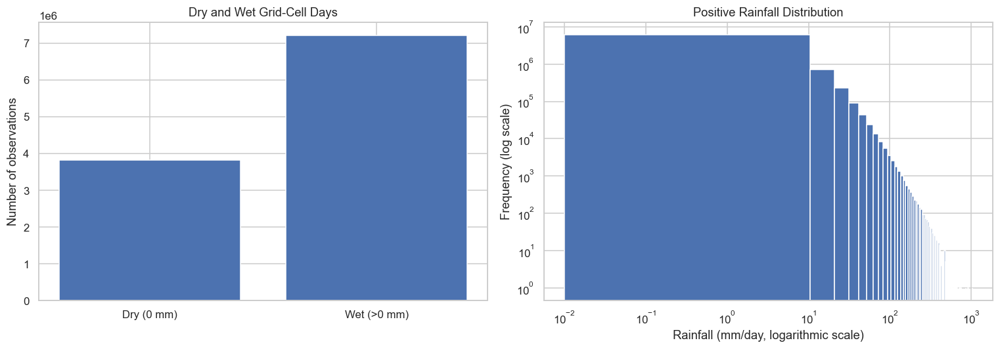

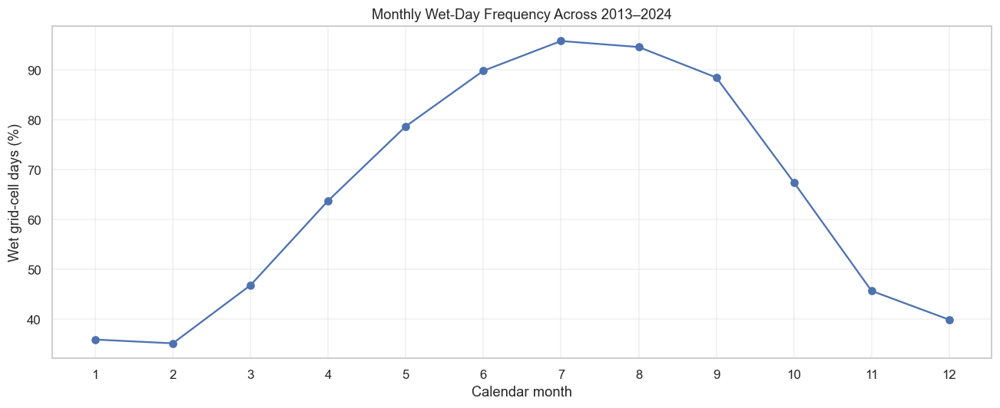


Rainfall exploratory analysis completed.


In [4]:

# ============================================================
# WI-02 | CELL 4: RAINFALL DISTRIBUTION AND WET-DAY FREQUENCY
# ============================================================

RAIN_COL = "PRECTOTCORR"

# Separate dry and wet grid-cell days
rain = weather[RAIN_COL]

dry_mask = rain == 0
wet_mask = rain > 0

total_observations = len(rain)
dry_count = int(dry_mask.sum())
wet_count = int(wet_mask.sum())

rainfall_summary = {
    "total_grid_cell_days": total_observations,
    "dry_grid_cell_days": dry_count,
    "wet_grid_cell_days": wet_count,
    "dry_percentage": round(dry_count / total_observations * 100, 3),
    "wet_percentage": round(wet_count / total_observations * 100, 3),
    "overall_mean_mm_day": round(float(rain.mean()), 4),
    "overall_median_mm_day": round(float(rain.median()), 4),
    "wet_day_mean_mm_day": round(float(rain[wet_mask].mean()), 4),
    "wet_day_median_mm_day": round(float(rain[wet_mask].median()), 4),
    "wet_day_quantiles_mm_day": {
        str(q): round(float(rain[wet_mask].quantile(q)), 4)
        for q in [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    },
    "maximum_mm_day": round(float(rain.max()), 4),
}

print("=" * 65)
print("RAINFALL DISTRIBUTION")
print("=" * 65)

for key, value in rainfall_summary.items():
    print(f"{key}: {value}")

# Annual wet-day frequency across all grid-cell days
annual_rainfall = (
    weather.assign(is_wet=wet_mask.astype("int8"))
    .groupby("year")
    .agg(
        total_grid_cell_days=(RAIN_COL, "size"),
        wet_grid_cell_days=("is_wet", "sum"),
        mean_rainfall_mm_day=(RAIN_COL, "mean"),
        median_rainfall_mm_day=(RAIN_COL, "median"),
    )
)

annual_rainfall["wet_day_percentage"] = (
    annual_rainfall["wet_grid_cell_days"]
    / annual_rainfall["total_grid_cell_days"] * 100
)

print("\nANNUAL RAINFALL SUMMARY")
display(annual_rainfall.round(3))

# Monthly wet-day frequency across all years and grid cells
monthly_rainfall = (
    weather.assign(
        month=weather["date"].dt.month,
        is_wet=wet_mask.astype("int8")
    )
    .groupby("month")
    .agg(
        grid_cell_days=(RAIN_COL, "size"),
        wet_grid_cell_days=("is_wet", "sum"),
        mean_rainfall_mm_day=(RAIN_COL, "mean"),
        median_rainfall_mm_day=(RAIN_COL, "median"),
    )
)

monthly_rainfall["wet_day_percentage"] = (
    monthly_rainfall["wet_grid_cell_days"]
    / monthly_rainfall["grid_cell_days"] * 100
)

print("\nMONTHLY RAINFALL SUMMARY (ALL YEARS)")
display(monthly_rainfall.round(3))

# Extreme rainfall observation counts
extreme_thresholds = [50, 100, 200, 300, 500]

extreme_counts = pd.DataFrame({
    "threshold_mm_day": extreme_thresholds,
    "grid_cell_days_at_or_above": [
        int((rain >= threshold).sum())
        for threshold in extreme_thresholds
    ]
})

extreme_counts["percentage_of_all_observations"] = (
    extreme_counts["grid_cell_days_at_or_above"]
    / total_observations * 100
)

print("\nHIGH-RAINFALL OBSERVATIONS")
display(extreme_counts.round(5))

# Plot 1: Wet versus dry observations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    ["Dry (0 mm)", "Wet (>0 mm)"],
    [dry_count, wet_count]
)
axes[0].set_title("Dry and Wet Grid-Cell Days")
axes[0].set_ylabel("Number of observations")

# Plot 2: Positive rainfall distribution, logarithmic x-axis
positive_rain = rain[wet_mask]

axes[1].hist(
    positive_rain,
    bins=100,
    log=True
)
axes[1].set_xscale("log")
axes[1].set_title("Positive Rainfall Distribution")
axes[1].set_xlabel("Rainfall (mm/day, logarithmic scale)")
axes[1].set_ylabel("Frequency (log scale)")

plt.tight_layout()
plt.show()

# Plot 3: Monthly wet-day frequency
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_rainfall.index,
    monthly_rainfall["wet_day_percentage"],
    marker="o"
)
plt.xticks(range(1, 13))
plt.xlabel("Calendar month")
plt.ylabel("Wet grid-cell days (%)")
plt.title("Monthly Wet-Day Frequency Across 2013–2024")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nRainfall exploratory analysis completed.")


YEAR-BY-MONTH WET-DAY FREQUENCY (%)


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2013,24.31,40.86,37.35,58.73,71.53,90.98,96.28,93.34,88.11,75.75,42.66,31.48
2014,30.04,34.49,37.62,58.00,77.24,82.11,94.01,93.15,86.33,66.59,39.50,39.73
2015,40.88,35.75,51.33,73.15,75.38,90.78,91.43,92.85,79.88,62.99,48.18,39.58
2016,33.77,34.36,46.44,54.94,79.81,91.07,96.29,95.23,87.88,60.14,35.08,32.59
2017,37.25,26.85,50.00,61.19,82.40,92.59,96.43,94.71,86.35,65.78,44.74,38.40
2018,28.63,33.06,45.18,71.60,78.47,89.94,94.78,95.15,84.46,57.80,42.26,39.45
2019,34.68,42.65,44.98,63.89,72.06,86.85,95.12,95.69,93.73,75.82,55.11,44.11
2020,45.33,35.08,57.60,72.67,79.95,94.17,97.17,95.92,87.57,66.69,49.25,39.45
2021,37.00,31.23,46.73,66.12,88.80,92.84,95.59,93.92,94.80,72.20,51.39,45.94


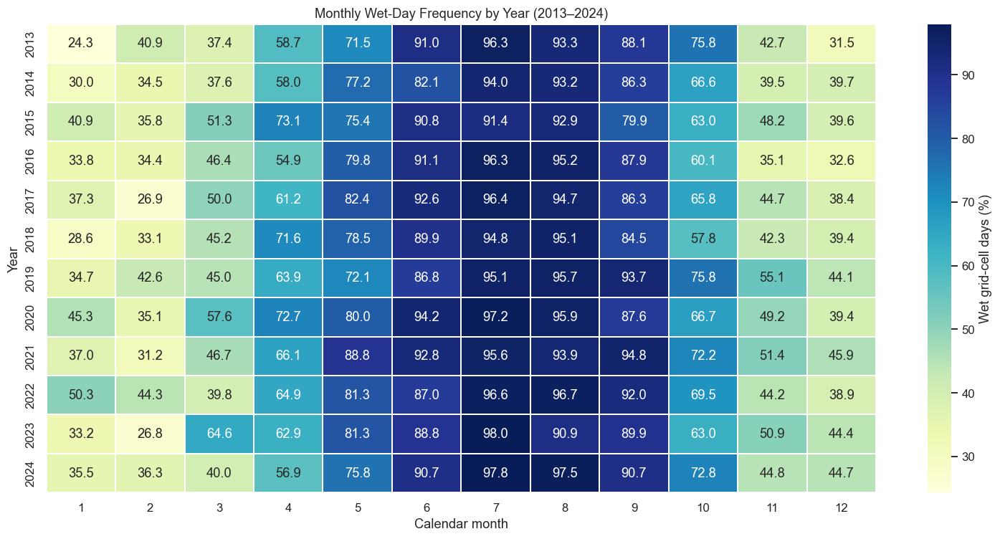


SEASONAL SUMMARY ACROSS YEARS


,mean_wet_day_percentage,std_wet_day_percentage,min_wet_day_percentage,max_wet_day_percentage,mean_rainfall_mm_day
calendar_season,,,,,
Winter (Dec-Feb),37.038,3.685,31.929,44.490,0.946
Pre-monsoon (Mar-May),63.066,4.819,55.837,70.043,2.001
Monsoon (Jun-Sep),92.216,1.805,88.791,94.294,7.335
Post-monsoon (Oct-Nov),56.729,4.853,47.816,65.637,3.006


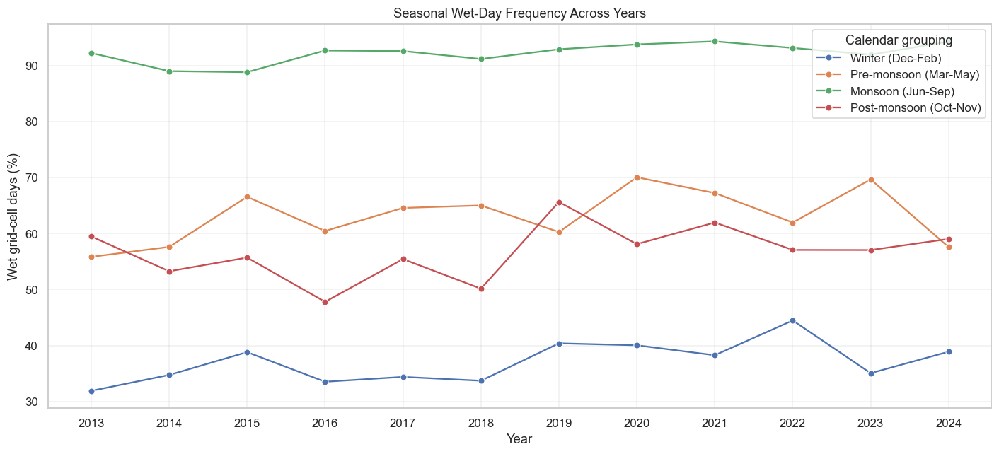


Seasonality findings saved to: C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_seasonality_findings.json
Seasonal analysis completed.


In [5]:

# ============================================================
# WI-02 | CELL 5: SEASONALITY AND YEAR-TO-YEAR VARIATION
# ============================================================

# Build a compact year-month summary from the daily observations
monthly_by_year = (
    weather.assign(
        month=weather["date"].dt.month,
        is_wet=(weather[RAIN_COL] > 0).astype("int8")
    )
    .groupby(["year", "month"], observed=True)
    .agg(
        grid_cell_days=(RAIN_COL, "size"),
        wet_grid_cell_days=("is_wet", "sum"),
        mean_rainfall_mm_day=(RAIN_COL, "mean")
    )
    .reset_index()
)

monthly_by_year["wet_day_percentage"] = (
    monthly_by_year["wet_grid_cell_days"]
    / monthly_by_year["grid_cell_days"] * 100
)

# Year x month matrix
wet_frequency_matrix = monthly_by_year.pivot(
    index="year",
    columns="month",
    values="wet_day_percentage"
)

print("=" * 65)
print("YEAR-BY-MONTH WET-DAY FREQUENCY (%)")
print("=" * 65)
display(wet_frequency_matrix.round(2))

# Heatmap: monthly variation across years
plt.figure(figsize=(14, 7))
sns.heatmap(
    wet_frequency_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Wet grid-cell days (%)"}
)
plt.title("Monthly Wet-Day Frequency by Year (2013–2024)")
plt.xlabel("Calendar month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

# Broad calendar-season definitions
def assign_calendar_season(month):
    if month in [12, 1, 2]:
        return "Winter (Dec-Feb)"
    elif month in [3, 4, 5]:
        return "Pre-monsoon (Mar-May)"
    elif month in [6, 7, 8, 9]:
        return "Monsoon (Jun-Sep)"
    else:
        return "Post-monsoon (Oct-Nov)"

monthly_by_year["calendar_season"] = (
    monthly_by_year["month"].apply(assign_calendar_season)
)

# Aggregate from monthly counts, not by averaging monthly percentages.
# This correctly accounts for differing numbers of days per month.
seasonal_by_year = (
    weather.assign(
        calendar_season=weather["date"].dt.month.map(
            assign_calendar_season
        ),
        is_wet=(weather[RAIN_COL] > 0).astype("int8")
    )
    .groupby(["year", "calendar_season"], observed=True)
    .agg(
        grid_cell_days=(RAIN_COL, "size"),
        wet_grid_cell_days=("is_wet", "sum"),
        mean_rainfall_mm_day=(RAIN_COL, "mean")
    )
    .reset_index()
)

seasonal_by_year["wet_day_percentage"] = (
    seasonal_by_year["wet_grid_cell_days"]
    / seasonal_by_year["grid_cell_days"] * 100
)

season_order = [
    "Winter (Dec-Feb)",
    "Pre-monsoon (Mar-May)",
    "Monsoon (Jun-Sep)",
    "Post-monsoon (Oct-Nov)"
]

seasonal_by_year["calendar_season"] = pd.Categorical(
    seasonal_by_year["calendar_season"],
    categories=season_order,
    ordered=True
)

seasonal_summary = (
    seasonal_by_year
    .groupby("calendar_season", observed=False)
    .agg(
        mean_wet_day_percentage=("wet_day_percentage", "mean"),
        std_wet_day_percentage=("wet_day_percentage", "std"),
        min_wet_day_percentage=("wet_day_percentage", "min"),
        max_wet_day_percentage=("wet_day_percentage", "max"),
        mean_rainfall_mm_day=("mean_rainfall_mm_day", "mean")
    )
)

print("\nSEASONAL SUMMARY ACROSS YEARS")
display(seasonal_summary.round(3))

# Plot year-to-year seasonal wet-day frequency
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=seasonal_by_year,
    x="year",
    y="wet_day_percentage",
    hue="calendar_season",
    marker="o"
)

plt.title("Seasonal Wet-Day Frequency Across Years")
plt.xlabel("Year")
plt.ylabel("Wet grid-cell days (%)")
plt.xticks(sorted(weather["year"].unique()))
plt.grid(True, alpha=0.3)
plt.legend(title="Calendar grouping")
plt.tight_layout()
plt.show()

# Save compact findings for later notebook handoff
seasonality_findings = {
    "year_month_wet_day_frequency_percent": (
        wet_frequency_matrix.round(4).to_dict()
    ),
    "seasonal_summary": (
        seasonal_summary.round(4).to_dict(orient="index")
    ),
    "season_definitions": {
        "Winter (Dec-Feb)": [12, 1, 2],
        "Pre-monsoon (Mar-May)": [3, 4, 5],
        "Monsoon (Jun-Sep)": [6, 7, 8, 9],
        "Post-monsoon (Oct-Nov)": [10, 11]
    },
    "interpretation_scope": (
        "Pooled grid-cell-day descriptive statistics; "
        "not district-level or crop-season measurements."
    )
}

seasonality_path = OUTPUT_DIR / "WI_02_seasonality_findings.json"

with open(seasonality_path, "w", encoding="utf-8") as file:
    json.dump(seasonality_findings, file, indent=2, ensure_ascii=False)

print("\nSeasonality findings saved to:", seasonality_path)
print("Seasonal analysis completed.")


SPATIAL RAINFALL SUMMARY
Grid cells: 2520
Latitude range: 7.0 to 34.5
Longitude range: 69.375 to 96.875

DISTRIBUTION OF GRID-CELL METRICS


,wet_day_percentage,mean_rainfall_mm_day,median_rainfall_mm_day,p95_rainfall_mm_day
count,2520.000,2520.000,2520.000,2520.000
mean,65.313,3.690,0.694,17.045
std,18.473,2.489,0.864,10.849
min,20.123,0.275,0.000,1.149
5%,34.063,0.898,0.000,4.567
25%,52.316,1.977,0.010,10.349
50%,64.636,3.445,0.250,15.987
75%,78.747,4.884,1.210,20.572
95%,95.643,7.498,2.560,34.969
max,99.247,19.799,3.370,90.133



10 GRID CELLS WITH LOWEST WET-DAY FREQUENCY


,cell_id,latitude,longitude,wet_day_percentage,mean_rainfall_mm_day
1710,cell_1710,26.0,69.375,20.123,0.758
1665,cell_1665,25.5,69.375,20.853,0.797
1755,cell_1755,26.5,69.375,21.332,0.747
1620,cell_1620,25.0,69.375,22.131,0.898
1800,cell_1800,27.0,69.375,22.177,0.743
1711,cell_1711,26.0,70.000,22.633,0.834
1845,cell_1845,27.5,69.375,22.770,0.744
1756,cell_1756,26.5,70.000,22.930,0.824
1801,cell_1801,27.0,70.000,23.409,0.814
1890,cell_1890,28.0,69.375,23.523,0.802



10 GRID CELLS WITH HIGHEST WET-DAY FREQUENCY


,cell_id,latitude,longitude,wet_day_percentage,mean_rainfall_mm_day
38,cell_0038,7.0,93.125,99.247,5.576
40,cell_0040,7.0,94.375,99.224,5.384
37,cell_0037,7.0,92.500,99.156,5.883
39,cell_0039,7.0,93.750,99.156,5.400
41,cell_0041,7.0,95.000,99.110,5.535
83,cell_0083,7.5,93.125,99.019,5.513
85,cell_0085,7.5,94.375,98.950,5.286
84,cell_0084,7.5,93.750,98.905,5.332
42,cell_0042,7.0,95.625,98.836,5.416
86,cell_0086,7.5,95.000,98.836,5.261



GRID DIMENSIONS
Unique latitudes: 56
Unique longitudes: 45
Latitude spacing values: [0.5]
Longitude spacing values: [0.625]


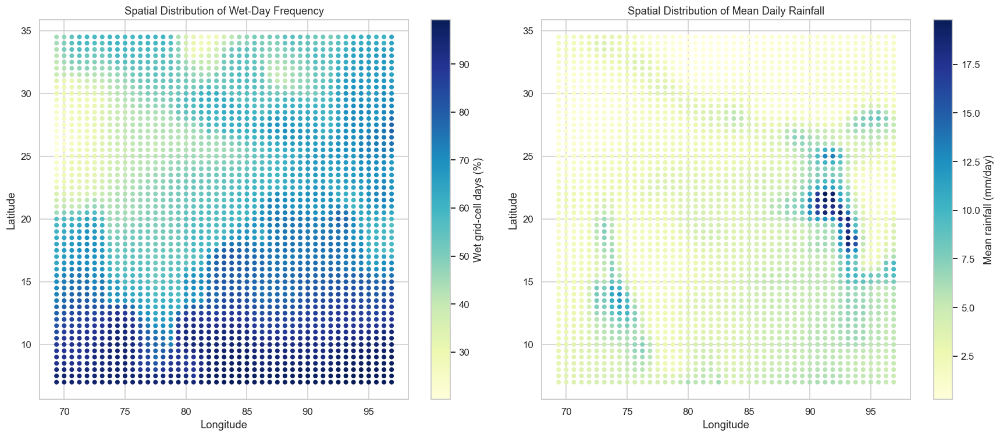


Per-cell spatial summary saved to: C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_spatial_rainfall_by_cell.csv
Spatial rainfall analysis completed.


In [6]:

# ============================================================
# WI-02 | CELL 6: SPATIAL VARIATION ACROSS WEATHER GRID CELLS
# ============================================================

# Aggregate daily observations for each grid cell
spatial_rainfall = (
    weather.groupby("cell_id", observed=True)
    .agg(
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        observation_count=(RAIN_COL, "size"),
        wet_day_count=(RAIN_COL, lambda values: (values > 0).sum()),
        mean_rainfall_mm_day=(RAIN_COL, "mean"),
        median_rainfall_mm_day=(RAIN_COL, "median"),
        p95_rainfall_mm_day=(
            RAIN_COL, lambda values: values.quantile(0.95)
        ),
    )
    .reset_index()
)

spatial_rainfall["wet_day_percentage"] = (
    spatial_rainfall["wet_day_count"]
    / spatial_rainfall["observation_count"] * 100
)

# Validate spatial aggregation
assert len(spatial_rainfall) == EXPECTED_GRID_CELLS
assert spatial_rainfall["observation_count"].eq(4383).all()
assert spatial_rainfall[
    ["latitude", "longitude", "wet_day_percentage",
     "mean_rainfall_mm_day", "p95_rainfall_mm_day"]
].notna().all().all()

print("=" * 65)
print("SPATIAL RAINFALL SUMMARY")
print("=" * 65)

print("Grid cells:", len(spatial_rainfall))
print(
    "Latitude range:",
    spatial_rainfall["latitude"].min(),
    "to",
    spatial_rainfall["latitude"].max()
)
print(
    "Longitude range:",
    spatial_rainfall["longitude"].min(),
    "to",
    spatial_rainfall["longitude"].max()
)

# Distribution across grid cells
spatial_metrics = [
    "wet_day_percentage",
    "mean_rainfall_mm_day",
    "median_rainfall_mm_day",
    "p95_rainfall_mm_day"
]

print("\nDISTRIBUTION OF GRID-CELL METRICS")
display(
    spatial_rainfall[spatial_metrics]
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
    .round(3)
)

# Identify cells at the lower and upper ends of wet-day frequency
print("\n10 GRID CELLS WITH LOWEST WET-DAY FREQUENCY")
display(
    spatial_rainfall.nsmallest(10, "wet_day_percentage")[
        ["cell_id", "latitude", "longitude",
         "wet_day_percentage", "mean_rainfall_mm_day"]
    ].round(3)
)

print("\n10 GRID CELLS WITH HIGHEST WET-DAY FREQUENCY")
display(
    spatial_rainfall.nlargest(10, "wet_day_percentage")[
        ["cell_id", "latitude", "longitude",
         "wet_day_percentage", "mean_rainfall_mm_day"]
    ].round(3)
)

# Check that coordinates form a regular grid
unique_latitudes = np.sort(spatial_rainfall["latitude"].unique())
unique_longitudes = np.sort(spatial_rainfall["longitude"].unique())

print("\nGRID DIMENSIONS")
print("Unique latitudes:", len(unique_latitudes))
print("Unique longitudes:", len(unique_longitudes))
print("Latitude spacing values:", np.unique(np.round(
    np.diff(unique_latitudes), 6
)))
print("Longitude spacing values:", np.unique(np.round(
    np.diff(unique_longitudes), 6
)))

# Spatial scatter plots
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

scatter_1 = axes[0].scatter(
    spatial_rainfall["longitude"],
    spatial_rainfall["latitude"],
    c=spatial_rainfall["wet_day_percentage"],
    cmap="YlGnBu",
    s=18
)
axes[0].set_title("Spatial Distribution of Wet-Day Frequency")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.colorbar(
    scatter_1, ax=axes[0],
    label="Wet grid-cell days (%)"
)

scatter_2 = axes[1].scatter(
    spatial_rainfall["longitude"],
    spatial_rainfall["latitude"],
    c=spatial_rainfall["mean_rainfall_mm_day"],
    cmap="YlGnBu",
    s=18
)
axes[1].set_title("Spatial Distribution of Mean Daily Rainfall")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
fig.colorbar(
    scatter_2, ax=axes[1],
    label="Mean rainfall (mm/day)"
)

plt.tight_layout()
plt.show()

# Save per-cell results for later spatial analysis
spatial_csv_path = OUTPUT_DIR / "WI_02_spatial_rainfall_by_cell.csv"
spatial_rainfall.to_csv(spatial_csv_path, index=False)

print("\nPer-cell spatial summary saved to:", spatial_csv_path)
print("Spatial rainfall analysis completed.")


SEASONAL SPATIAL COVERAGE


,unique_grid_cells
calendar_season,
Monsoon (Jun-Sep),2520
Post-monsoon (Oct-Nov),2520
Pre-monsoon (Mar-May),2520
Winter (Dec-Feb),2520



GEOGRAPHIC VARIATION BY SEASON


,mean_wet_day_percentage,std_wet_day_percentage,min_wet_day_percentage,median_wet_day_percentage,max_wet_day_percentage,mean_rainfall_mm_day,std_mean_rainfall_mm_day,min_cell_mean_rainfall,max_cell_mean_rainfall
calendar_season,,,,,,,,,
Winter (Dec-Feb),37.039,25.873,3.601,26.962,98.430,0.946,1.134,0.026,7.213
Pre-monsoon (Mar-May),63.066,21.528,9.511,66.667,98.913,2.001,1.752,0.080,14.038
Monsoon (Jun-Sep),92.216,12.039,36.270,97.951,100.000,7.335,5.576,0.643,44.550
Post-monsoon (Oct-Nov),56.729,31.430,6.421,52.049,100.000,3.006,2.737,0.053,14.592



Winter (Dec-Feb): LOWEST WET-DAY FREQUENCY


,cell_id,latitude,longitude,wet_day_percentage,mean_rainfall_mm_day
5583,cell_1395,22.5,69.375,3.601,0.029
5223,cell_1305,21.5,69.375,3.693,0.059
5403,cell_1350,22.0,69.375,3.786,0.041
5407,cell_1351,22.0,70.000,3.786,0.031
5763,cell_1440,23.0,69.375,3.786,0.026


... (11 outputs left out)

,cell_id,latitude,longitude,wet_day_percentage,mean_rainfall_mm_day
6841,cell_1710,26.0,69.375,6.421,0.083
7201,cell_1800,27.0,69.375,6.557,0.139
7205,cell_1801,27.0,70.000,6.557,0.162
7381,cell_1845,27.5,69.375,6.694,0.138
7021,cell_1755,26.5,69.375,6.967,0.118


Post-monsoon (Oct-Nov): HIGHEST WET-DAY FREQUENCY


,cell_id,latitude,longitude,wet_day_percentage,mean_rainfall_mm_day
113,cell_0028,7.0,86.875,100.0,7.455
117,cell_0029,7.0,87.500,100.0,7.373
137,cell_0034,7.0,90.625,100.0,7.809
141,cell_0035,7.0,91.250,100.0,7.801
145,cell_0036,7.0,91.875,100.0,7.797


C:\Users\gsr58\AppData\Local\Temp\ipykernel_1444\842640575.py:141: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


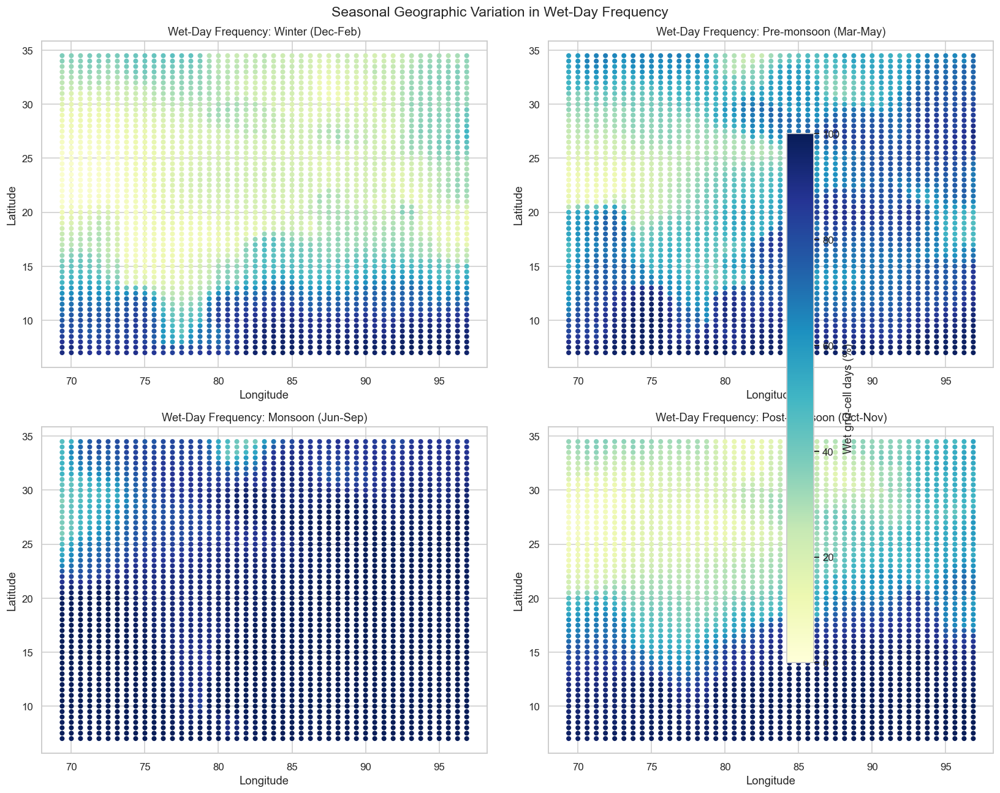

C:\Users\gsr58\AppData\Local\Temp\ipykernel_1444\842640575.py:182: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


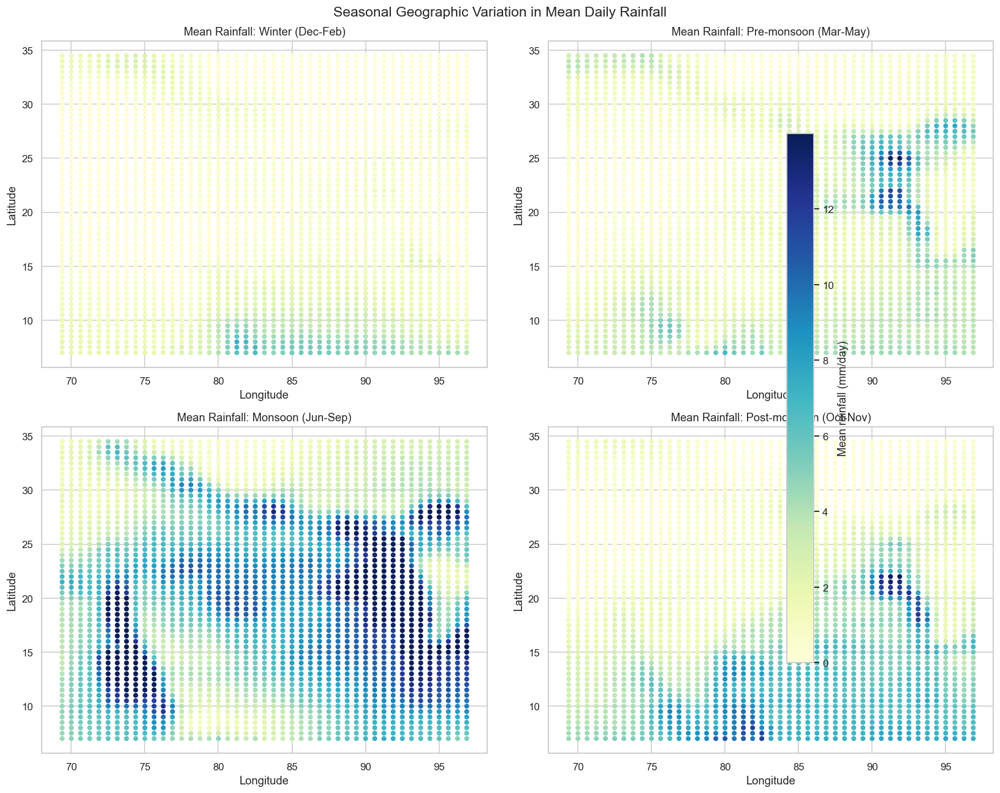


Seasonal spatial summary saved to: C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_seasonal_spatial_rainfall_by_cell.csv
Seasonal geographic analysis completed.


In [7]:

# ============================================================
# WI-02 | CELL 7: SEASONAL GEOGRAPHIC VARIATION
# ============================================================

# Assign calendar groupings consistently with Cell 5
def assign_calendar_season(month):
    if month in [12, 1, 2]:
        return "Winter (Dec-Feb)"
    elif month in [3, 4, 5]:
        return "Pre-monsoon (Mar-May)"
    elif month in [6, 7, 8, 9]:
        return "Monsoon (Jun-Sep)"
    else:
        return "Post-monsoon (Oct-Nov)"

season_order = [
    "Winter (Dec-Feb)",
    "Pre-monsoon (Mar-May)",
    "Monsoon (Jun-Sep)",
    "Post-monsoon (Oct-Nov)"
]

# Aggregate grid-cell observations by calendar grouping
weather_seasonal = weather.assign(
    calendar_season=weather["date"].dt.month.map(
        assign_calendar_season
    ),
    is_wet=(weather[RAIN_COL] > 0).astype("int8")
)

seasonal_spatial = (
    weather_seasonal
    .groupby(["cell_id", "calendar_season"], observed=True)
    .agg(
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        observation_count=(RAIN_COL, "size"),
        wet_day_count=("is_wet", "sum"),
        mean_rainfall_mm_day=(RAIN_COL, "mean"),
        p95_rainfall_mm_day=(
            RAIN_COL, lambda values: values.quantile(0.95)
        )
    )
    .reset_index()
)

seasonal_spatial["wet_day_percentage"] = (
    seasonal_spatial["wet_day_count"]
    / seasonal_spatial["observation_count"] * 100
)

# Validate expected seasonal coverage for every grid cell
seasonal_counts = seasonal_spatial.groupby(
    "calendar_season", observed=True
)["cell_id"].nunique()

print("=" * 65)
print("SEASONAL SPATIAL COVERAGE")
print("=" * 65)
display(seasonal_counts.to_frame("unique_grid_cells"))

assert seasonal_counts.eq(EXPECTED_GRID_CELLS).all()
assert seasonal_spatial["wet_day_percentage"].between(0, 100).all()

# Summary of geographic variation within each season
seasonal_spatial_summary = (
    seasonal_spatial
    .groupby("calendar_season", observed=True)
    .agg(
        mean_wet_day_percentage=("wet_day_percentage", "mean"),
        std_wet_day_percentage=("wet_day_percentage", "std"),
        min_wet_day_percentage=("wet_day_percentage", "min"),
        median_wet_day_percentage=("wet_day_percentage", "median"),
        max_wet_day_percentage=("wet_day_percentage", "max"),
        mean_rainfall_mm_day=("mean_rainfall_mm_day", "mean"),
        std_mean_rainfall_mm_day=("mean_rainfall_mm_day", "std"),
        min_cell_mean_rainfall=("mean_rainfall_mm_day", "min"),
        max_cell_mean_rainfall=("mean_rainfall_mm_day", "max")
    )
    .reindex(season_order)
)

print("\nGEOGRAPHIC VARIATION BY SEASON")
display(seasonal_spatial_summary.round(3))

# Show the wettest and driest cells in each season
for season in season_order:
    subset = seasonal_spatial[
        seasonal_spatial["calendar_season"] == season
    ]

    print(f"\n{season}: LOWEST WET-DAY FREQUENCY")
    display(
        subset.nsmallest(5, "wet_day_percentage")[
            ["cell_id", "latitude", "longitude",
             "wet_day_percentage", "mean_rainfall_mm_day"]
        ].round(3)
    )

    print(f"{season}: HIGHEST WET-DAY FREQUENCY")
    display(
        subset.nlargest(5, "wet_day_percentage")[
            ["cell_id", "latitude", "longitude",
             "wet_day_percentage", "mean_rainfall_mm_day"]
        ].round(3)
    )

# Plot seasonal wet-day frequency maps
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for ax, season in zip(axes, season_order):
    subset = seasonal_spatial[
        seasonal_spatial["calendar_season"] == season
    ]

    scatter = ax.scatter(
        subset["longitude"],
        subset["latitude"],
        c=subset["wet_day_percentage"],
        cmap="YlGnBu",
        s=18,
        vmin=0,
        vmax=100
    )

    ax.set_title(f"Wet-Day Frequency: {season}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.colorbar(
    scatter,
    ax=axes.tolist(),
    label="Wet grid-cell days (%)",
    shrink=0.85
)
fig.suptitle(
    "Seasonal Geographic Variation in Wet-Day Frequency",
    fontsize=15
)
plt.tight_layout()
plt.show()

# Plot seasonal mean rainfall maps
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

# Shared colour scale makes seasonal panels more comparable
rainfall_vmax = seasonal_spatial[
    "mean_rainfall_mm_day"
].quantile(0.98)

for ax, season in zip(axes, season_order):
    subset = seasonal_spatial[
        seasonal_spatial["calendar_season"] == season
    ]

    scatter = ax.scatter(
        subset["longitude"],
        subset["latitude"],
        c=subset["mean_rainfall_mm_day"],
        cmap="YlGnBu",
        s=18,
        vmin=0,
        vmax=rainfall_vmax
    )

    ax.set_title(f"Mean Rainfall: {season}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.colorbar(
    scatter,
    ax=axes.tolist(),
    label="Mean rainfall (mm/day)",
    shrink=0.85
)
fig.suptitle(
    "Seasonal Geographic Variation in Mean Daily Rainfall",
    fontsize=15
)
plt.tight_layout()
plt.show()

# Save seasonal grid-cell summaries
seasonal_spatial_path = (
    OUTPUT_DIR / "WI_02_seasonal_spatial_rainfall_by_cell.csv"
)
seasonal_spatial.to_csv(seasonal_spatial_path, index=False)

print("\nSeasonal spatial summary saved to:", seasonal_spatial_path)
print("Seasonal geographic analysis completed.")


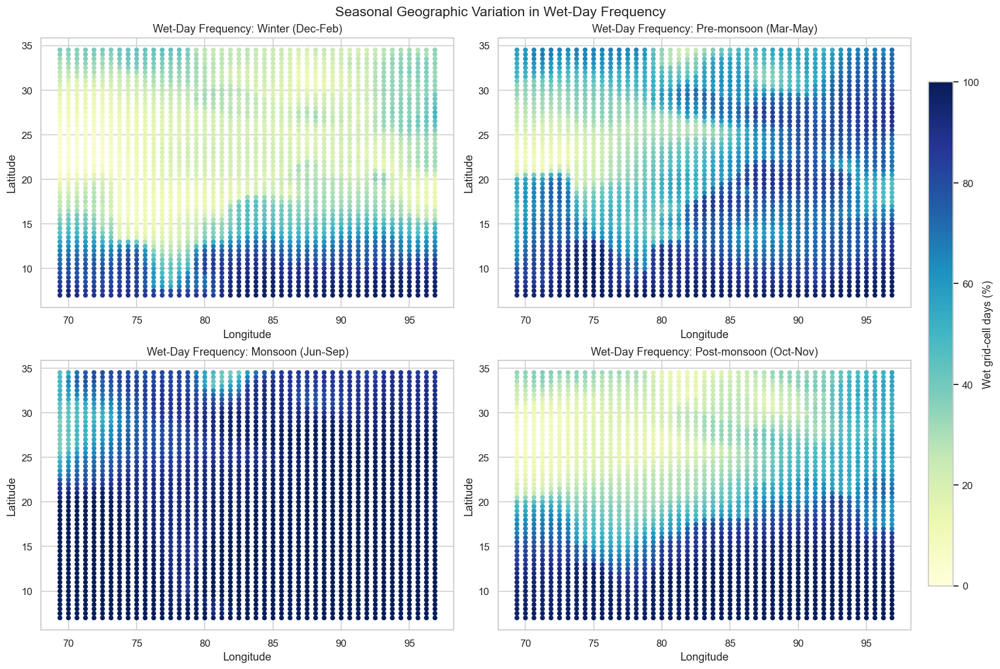

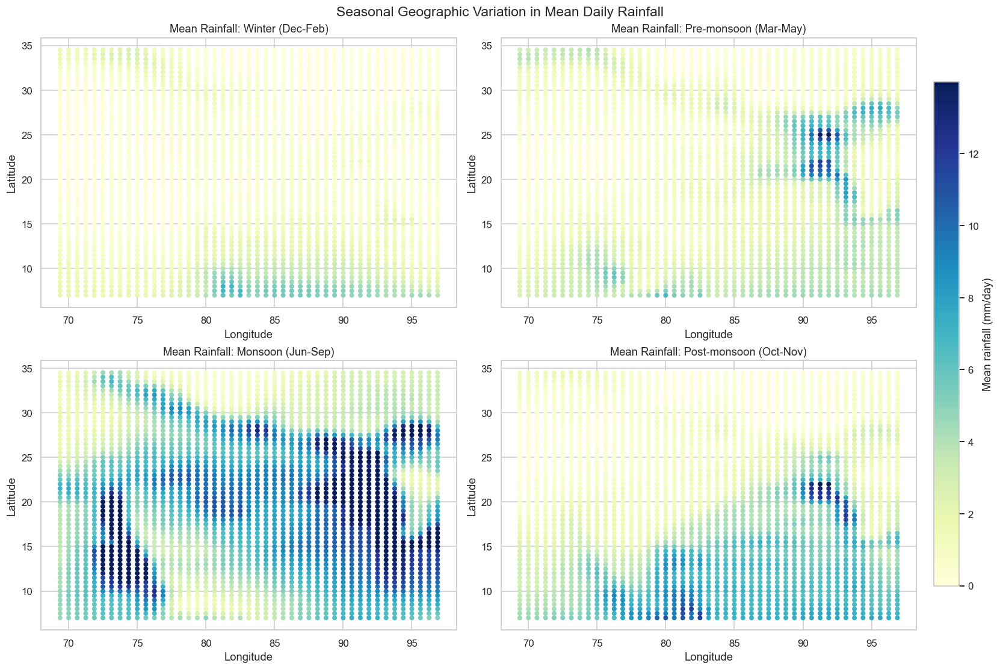

Corrected seasonal maps generated.


In [8]:

# ============================================================
# WI-02 | CELL 7A: REGENERATE SEASONAL MAPS WITH CLEAN LAYOUT
# ============================================================

# Wet-day frequency maps
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10),
    constrained_layout=True
)
axes = axes.flatten()

for ax, season in zip(axes, season_order):
    subset = seasonal_spatial[
        seasonal_spatial["calendar_season"] == season
    ]

    scatter = ax.scatter(
        subset["longitude"],
        subset["latitude"],
        c=subset["wet_day_percentage"],
        cmap="YlGnBu",
        s=18,
        vmin=0,
        vmax=100
    )

    ax.set_title(f"Wet-Day Frequency: {season}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.colorbar(
    scatter,
    ax=axes.tolist(),
    label="Wet grid-cell days (%)",
    shrink=0.85,
    pad=0.02
)

fig.suptitle(
    "Seasonal Geographic Variation in Wet-Day Frequency",
    fontsize=15
)
plt.show()


# Mean rainfall maps
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10),
    constrained_layout=True
)
axes = axes.flatten()

rainfall_vmax = seasonal_spatial[
    "mean_rainfall_mm_day"
].quantile(0.98)

for ax, season in zip(axes, season_order):
    subset = seasonal_spatial[
        seasonal_spatial["calendar_season"] == season
    ]

    scatter = ax.scatter(
        subset["longitude"],
        subset["latitude"],
        c=subset["mean_rainfall_mm_day"],
        cmap="YlGnBu",
        s=18,
        vmin=0,
        vmax=rainfall_vmax
    )

    ax.set_title(f"Mean Rainfall: {season}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

fig.colorbar(
    scatter,
    ax=axes.tolist(),
    label="Mean rainfall (mm/day)",
    shrink=0.85,
    pad=0.02
)

fig.suptitle(
    "Seasonal Geographic Variation in Mean Daily Rainfall",
    fontsize=15
)
plt.show()

print("Corrected seasonal maps generated.")


TEMPERATURE DISTRIBUTION SUMMARY


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
T2M_MAX,11045160.0,25.928,10.951,-24.19,-9.39,-0.36,25.59,28.57,30.76,39.75,43.87,46.85,51.51
T2M_MIN,11045160.0,17.936,13.542,-42.81,-23.51,-13.77,12.93,23.97,27.51,29.06,30.12,32.66,37.98
TEMP_RANGE,11045160.0,7.993,6.417,0.04,0.23,0.36,0.82,8.24,13.74,17.85,19.80,21.74,30.20



TEMPERATURE QUANTILES (°C)


,0.1_percentile,1_percentile,5_percentile,median,95_percentile,99_percentile,99.9_percentile
T2M_MAX,-15.27,-9.39,-0.36,28.57,39.75,43.87,46.85
T2M_MIN,-30.15,-23.51,-13.77,23.97,29.06,30.12,32.66
TEMP_RANGE,0.15,0.23,0.36,8.24,17.85,19.80,21.74



TEMPERATURE THRESHOLD COUNTS
T2M_MAX_above_35C: 1,352,170 (12.2422%)
T2M_MAX_above_40C: 517,548 (4.6857%)
T2M_MAX_above_45C: 53,554 (0.4849%)
T2M_MAX_above_50C: 66 (0.0006%)
T2M_MIN_below_0C: 1,441,321 (13.0493%)
T2M_MIN_below_minus_5C: 1,034,443 (9.3656%)
T2M_MIN_below_minus_10C: 704,558 (6.3789%)
T2M_MIN_below_minus_20C: 254,599 (2.3051%)

10 HIGHEST DAILY MAXIMUM TEMPERATURE OBSERVATIONS


,cell_id,latitude,longitude,date,T2M_MAX,T2M_MIN,TEMP_RANGE
10814727,cell_1890,28.0,69.375,2024-05-27,51.51,30.24,21.27
10831563,cell_1936,28.5,70.000,2024-05-27,51.30,31.22,20.08
10848400,cell_1982,29.0,70.625,2024-05-28,51.30,31.21,20.09
10831197,cell_1935,28.5,69.375,2024-05-27,51.18,31.40,19.78
10831564,cell_1936,28.5,70.000,2024-05-28,51.18,30.90,20.28
10748848,cell_1710,26.0,69.375,2024-05-28,51.17,28.89,22.28
10831930,cell_1937,28.5,70.625,2024-05-28,51.11,30.89,20.22
10831562,cell_1936,28.5,70.000,2024-05-26,51.09,31.95,19.14
10815092,cell_1891,28.0,70.000,2024-05-26,51.05,30.85,20.20
10848399,cell_1982,29.0,70.625,2024-05-27,51.00,31.35,19.65



10 LOWEST DAILY MINIMUM TEMPERATURE OBSERVATIONS


,cell_id,latitude,longitude,date,T2M_MAX,T2M_MIN,TEMP_RANGE
763238,cell_2091,30.0,82.500,2013-01-24,-14.30,-42.81,28.51
6430164,cell_2489,34.5,78.125,2019-12-26,-21.15,-42.19,21.04
6396616,cell_2398,33.5,77.500,2019-01-27,-18.49,-41.90,23.41
6414104,cell_2445,34.0,78.750,2019-12-26,-19.30,-41.20,21.90
6430163,cell_2489,34.5,78.125,2019-12-25,-21.48,-40.75,19.27
7206811,cell_2092,30.0,83.125,2020-01-20,-13.87,-40.35,26.48
6284885,cell_2091,30.0,82.500,2019-12-17,-11.97,-40.31,28.34
7272691,cell_2272,32.0,83.125,2020-01-20,-13.44,-40.20,26.76
6396615,cell_2398,33.5,77.500,2019-01-26,-18.66,-40.17,21.51
6397670,cell_2400,33.5,78.750,2019-12-17,-16.06,-40.10,24.04



TEMPERATURE CORRELATION MATRIX


,T2M_MAX,T2M_MIN,TEMP_RANGE
T2M_MAX,1.000,0.884,-0.159
T2M_MIN,0.884,1.000,-0.602
TEMP_RANGE,-0.159,-0.602,1.000


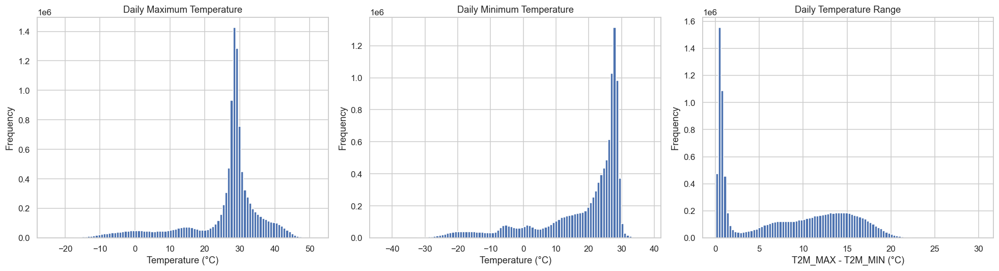

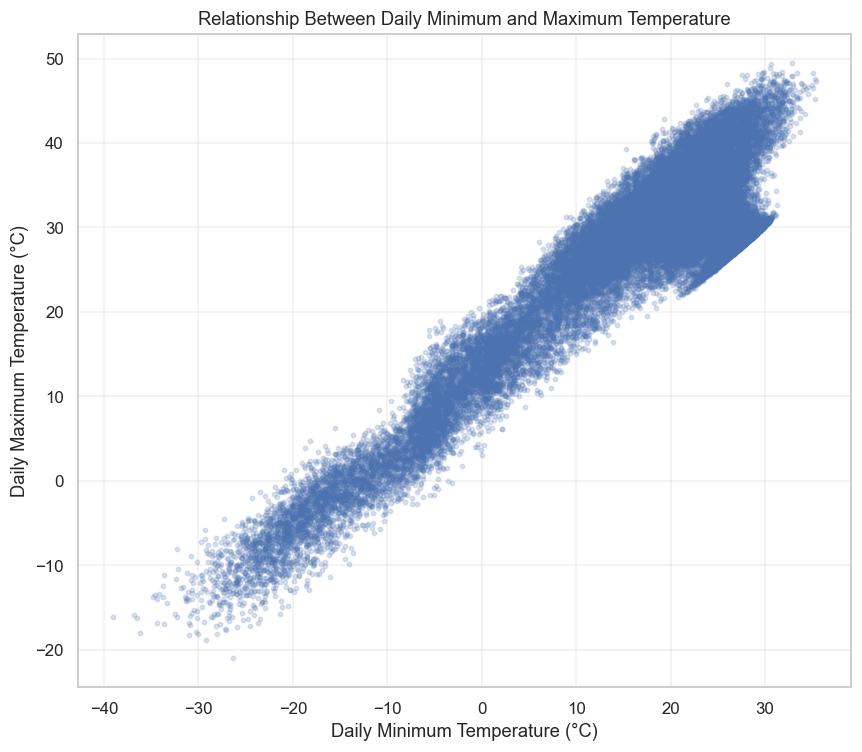


Temperature findings saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_temperature_distribution_findings.json

Temperature distribution analysis completed.


In [9]:

# ============================================================
# WI-02 | CELL 8: TEMPERATURE DISTRIBUTION ANALYSIS
# ============================================================

TMAX_COL = "T2M_MAX"
TMIN_COL = "T2M_MIN"

# Derive daily temperature range
weather["TEMP_RANGE"] = weather[TMAX_COL] - weather[TMIN_COL]

# Validate the derived variable
assert weather["TEMP_RANGE"].notna().all()
assert (weather["TEMP_RANGE"] >= 0).all()

# Summary statistics
temperature_variables = [
    TMAX_COL,
    TMIN_COL,
    "TEMP_RANGE"
]

temperature_summary = weather[
    temperature_variables
].describe(
    percentiles=[
        0.01, 0.05, 0.25, 0.50,
        0.75, 0.95, 0.99, 0.999
    ]
).T

print("=" * 65)
print("TEMPERATURE DISTRIBUTION SUMMARY")
print("=" * 65)
display(temperature_summary.round(3))

# Additional quantile analysis
temperature_quantiles = (
    weather[temperature_variables]
    .quantile([0.001, 0.01, 0.05, 0.50, 0.95, 0.99, 0.999])
    .T
)

temperature_quantiles.columns = [
    "0.1_percentile",
    "1_percentile",
    "5_percentile",
    "median",
    "95_percentile",
    "99_percentile",
    "99.9_percentile"
]

print("\nTEMPERATURE QUANTILES (°C)")
display(temperature_quantiles.round(3))

# Descriptive threshold counts
temperature_thresholds = {
    "T2M_MAX_above_35C": int((weather[TMAX_COL] > 35).sum()),
    "T2M_MAX_above_40C": int((weather[TMAX_COL] > 40).sum()),
    "T2M_MAX_above_45C": int((weather[TMAX_COL] > 45).sum()),
    "T2M_MAX_above_50C": int((weather[TMAX_COL] > 50).sum()),
    "T2M_MIN_below_0C": int((weather[TMIN_COL] < 0).sum()),
    "T2M_MIN_below_minus_5C": int((weather[TMIN_COL] < -5).sum()),
    "T2M_MIN_below_minus_10C": int((weather[TMIN_COL] < -10).sum()),
    "T2M_MIN_below_minus_20C": int((weather[TMIN_COL] < -20).sum()),
}

print("\nTEMPERATURE THRESHOLD COUNTS")
for name, count in temperature_thresholds.items():
    percentage = count / len(weather) * 100
    print(f"{name}: {count:,} ({percentage:.4f}%)")

# Identify most extreme observations
print("\n10 HIGHEST DAILY MAXIMUM TEMPERATURE OBSERVATIONS")
display(
    weather.nlargest(10, TMAX_COL)[
        ["cell_id", "latitude", "longitude", "date",
         TMAX_COL, TMIN_COL, "TEMP_RANGE"]
    ].round(3)
)

print("\n10 LOWEST DAILY MINIMUM TEMPERATURE OBSERVATIONS")
display(
    weather.nsmallest(10, TMIN_COL)[
        ["cell_id", "latitude", "longitude", "date",
         TMAX_COL, TMIN_COL, "TEMP_RANGE"]
    ].round(3)
)

# Temperature relationship
temperature_correlation = weather[
    [TMAX_COL, TMIN_COL, "TEMP_RANGE"]
].corr()

print("\nTEMPERATURE CORRELATION MATRIX")
display(temperature_correlation.round(3))

# ------------------------------------------------------------
# Visualizations
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(
    weather[TMAX_COL],
    bins=100
)
axes[0].set_title("Daily Maximum Temperature")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Frequency")

axes[1].hist(
    weather[TMIN_COL],
    bins=100
)
axes[1].set_title("Daily Minimum Temperature")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Frequency")

axes[2].hist(
    weather["TEMP_RANGE"],
    bins=100
)
axes[2].set_title("Daily Temperature Range")
axes[2].set_xlabel("T2M_MAX - T2M_MIN (°C)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Relationship between maximum and minimum temperature
plt.figure(figsize=(8, 7))

sample_size = min(50_000, len(weather))
temperature_sample = weather.sample(
    n=sample_size,
    random_state=42
)

plt.scatter(
    temperature_sample[TMIN_COL],
    temperature_sample[TMAX_COL],
    alpha=0.2,
    s=8
)

plt.xlabel("Daily Minimum Temperature (°C)")
plt.ylabel("Daily Maximum Temperature (°C)")
plt.title("Relationship Between Daily Minimum and Maximum Temperature")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save findings
temperature_findings = {
    "summary_statistics": (
        temperature_summary.round(4).to_dict(orient="index")
    ),
    "quantiles": (
        temperature_quantiles.round(4).to_dict(orient="index")
    ),
    "threshold_counts": temperature_thresholds,
    "correlation_matrix": (
        temperature_correlation.round(4).to_dict()
    ),
    "extreme_values": {
        "maximum_T2M_MAX_C": float(weather[TMAX_COL].max()),
        "minimum_T2M_MIN_C": float(weather[TMIN_COL].min()),
        "maximum_temperature_range_C": float(
            weather["TEMP_RANGE"].max()
        )
    },
    "interpretation_note": (
        "Descriptive gridded weather statistics. "
        "Threshold counts do not independently establish "
        "heatwave, frost, or agricultural-risk events."
    )
}

temperature_findings_path = (
    OUTPUT_DIR / "WI_02_temperature_distribution_findings.json"
)

with open(
    temperature_findings_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        temperature_findings,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nTemperature findings saved to:")
print(temperature_findings_path)
print("\nTemperature distribution analysis completed.")


SEASONAL TEMPERATURE SUMMARY


,observation_count,mean_tmax_c,median_tmax_c,mean_tmin_c,median_tmin_c,mean_temp_range_c,median_temp_range_c,p95_tmax_c,p05_tmin_c
calendar_season,,,,,,,,,
Winter (Dec-Feb),2729160,21.500,26.58,12.175,15.11,9.326,11.49,32.76,-22.30
Pre-monsoon (Mar-May),2782080,28.149,29.76,19.045,24.90,9.104,10.98,42.54,-10.99
Monsoon (Jun-Sep),3689280,28.194,29.07,21.856,25.98,6.338,6.12,39.50,-1.33
Post-monsoon (Oct-Nov),1844640,24.600,28.33,16.945,20.99,7.655,8.55,34.00,-13.51



YEAR-BY-SEASON TEMPERATURE SUMMARY


,year,calendar_season,mean_tmax_c,mean_tmin_c,mean_temp_range_c
0,2013,Monsoon (Jun-Sep),27.726,21.534,6.191
1,2013,Post-monsoon (Oct-Nov),24.069,16.657,7.413
2,2013,Pre-monsoon (Mar-May),28.230,18.983,9.247
3,2013,Winter (Dec-Feb),21.342,11.849,9.493
4,2014,Monsoon (Jun-Sep),28.512,21.886,6.626
5,2014,Post-monsoon (Oct-Nov),24.696,16.788,7.909
6,2014,Pre-monsoon (Mar-May),27.875,18.763,9.112
7,2014,Winter (Dec-Feb),21.220,11.917,9.303
8,2015,Monsoon (Jun-Sep),28.294,21.617,6.677
9,2015,Post-monsoon (Oct-Nov),25.312,17.364,7.947



GEOGRAPHIC TEMPERATURE VARIATION BY SEASON


,mean_cell_tmax_c,std_cell_tmax_c,min_cell_tmax_c,max_cell_tmax_c,mean_cell_tmin_c,std_cell_tmin_c,min_cell_tmin_c,max_cell_tmin_c,mean_cell_temp_range_c
calendar_season,,,,,,,,,
Winter (Dec-Feb),21.500,12.285,-15.441,34.726,12.175,15.675,-27.881,27.593,9.326
Pre-monsoon (Mar-May),28.149,11.630,-5.654,41.195,19.045,12.932,-17.276,28.780,9.104
Monsoon (Jun-Sep),28.194,6.959,6.689,42.267,21.856,9.805,-5.153,30.001,6.338
Post-monsoon (Oct-Nov),24.600,9.947,-6.094,35.676,16.945,12.958,-17.380,28.199,7.655


... (14 outputs left out)


Post-monsoon (Oct-Nov): HIGHEST MEAN MAXIMUM TEMPERATURE


,cell_id,latitude,longitude,mean_tmax_c,mean_tmin_c
6661,cell_1665,25.5,69.375,35.676,19.856
6481,cell_1620,25.0,69.375,35.533,19.971
6841,cell_1710,26.0,69.375,35.338,19.938
5749,cell_1437,22.5,95.625,35.274,22.983
6301,cell_1575,24.5,69.375,35.135,20.008


Post-monsoon (Oct-Nov): LOWEST MEAN MINIMUM TEMPERATURE


,cell_id,latitude,longitude,mean_tmax_c,mean_tmin_c
9961,cell_2490,34.5,78.750,-5.935,-17.380
9965,cell_2491,34.5,79.375,-4.438,-16.775
10005,cell_2501,34.5,85.625,-3.762,-16.310
9969,cell_2492,34.5,80.000,-3.534,-16.171
9973,cell_2493,34.5,80.625,-2.870,-15.667


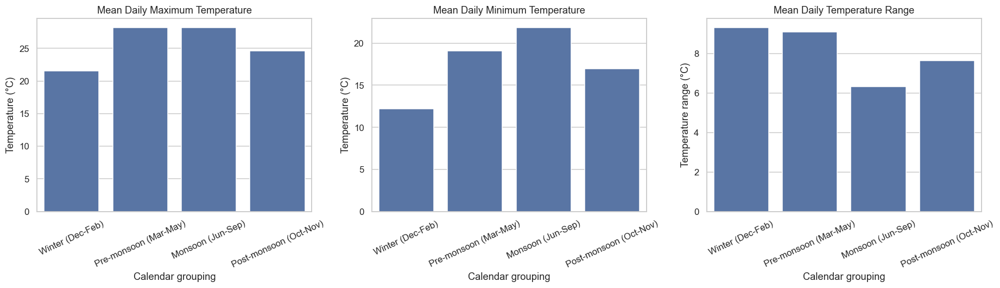

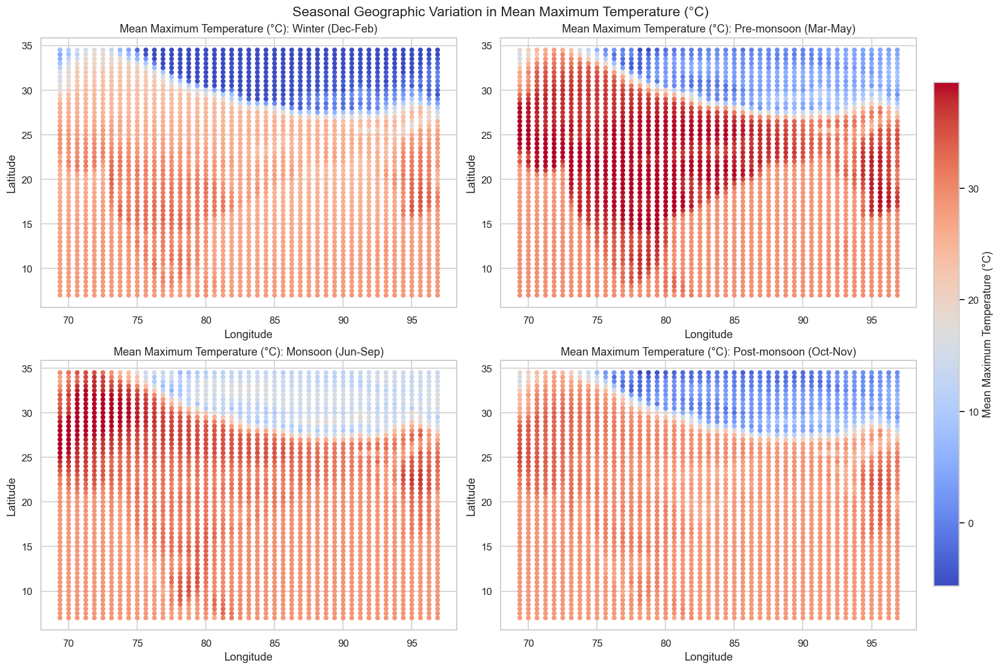

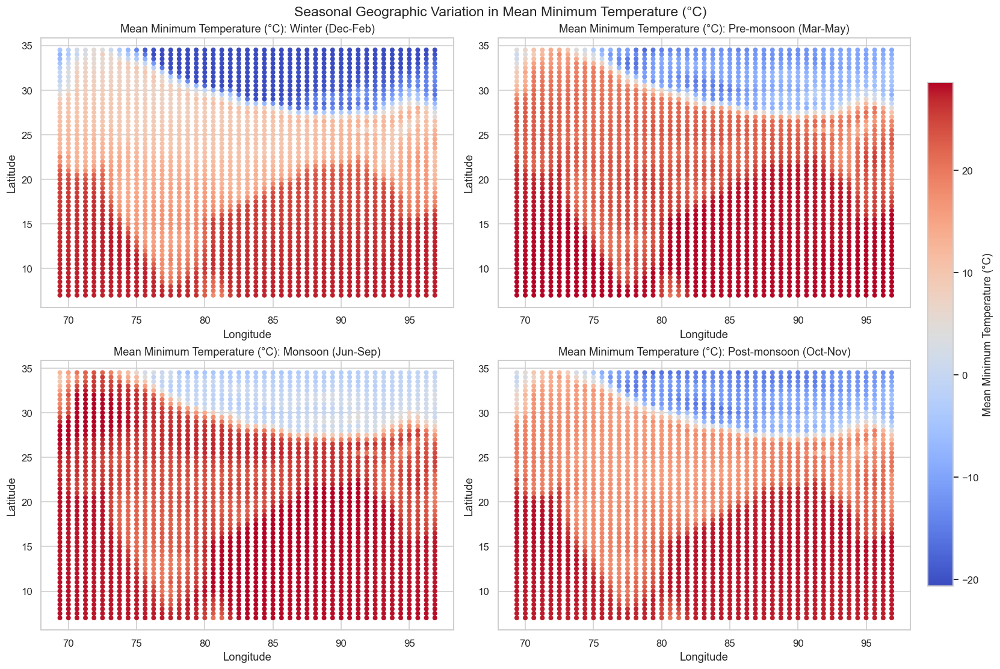


Seasonal temperature findings saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_seasonal_temperature_findings.json

Per-cell seasonal temperature summary saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_seasonal_temperature_by_cell.csv

Seasonal temperature analysis completed.


In [10]:

# ============================================================
# WI-02 | CELL 9: SEASONAL TEMPERATURE ANALYSIS
# ============================================================

# Reuse the calendar groupings from rainfall analysis
def assign_calendar_season(month):
    if month in [12, 1, 2]:
        return "Winter (Dec-Feb)"
    elif month in [3, 4, 5]:
        return "Pre-monsoon (Mar-May)"
    elif month in [6, 7, 8, 9]:
        return "Monsoon (Jun-Sep)"
    else:
        return "Post-monsoon (Oct-Nov)"

season_order = [
    "Winter (Dec-Feb)",
    "Pre-monsoon (Mar-May)",
    "Monsoon (Jun-Sep)",
    "Post-monsoon (Oct-Nov)"
]

# Add calendar grouping
weather["calendar_season"] = (
    weather["date"].dt.month.map(assign_calendar_season)
)

# ------------------------------------------------------------
# 1. Overall seasonal temperature summary
# ------------------------------------------------------------

seasonal_temperature = (
    weather.groupby("calendar_season", observed=True)
    .agg(
        observation_count=(TMAX_COL, "size"),
        mean_tmax_c=(TMAX_COL, "mean"),
        median_tmax_c=(TMAX_COL, "median"),
        mean_tmin_c=(TMIN_COL, "mean"),
        median_tmin_c=(TMIN_COL, "median"),
        mean_temp_range_c=("TEMP_RANGE", "mean"),
        median_temp_range_c=("TEMP_RANGE", "median"),
        p95_tmax_c=(TMAX_COL, lambda x: x.quantile(0.95)),
        p05_tmin_c=(TMIN_COL, lambda x: x.quantile(0.05))
    )
    .reindex(season_order)
)

print("=" * 65)
print("SEASONAL TEMPERATURE SUMMARY")
print("=" * 65)
display(seasonal_temperature.round(3))

# ------------------------------------------------------------
# 2. Year-by-season temperature summary
# ------------------------------------------------------------

seasonal_temperature_by_year = (
    weather.groupby(
        ["year", "calendar_season"],
        observed=True
    )
    .agg(
        mean_tmax_c=(TMAX_COL, "mean"),
        mean_tmin_c=(TMIN_COL, "mean"),
        mean_temp_range_c=("TEMP_RANGE", "mean")
    )
    .reset_index()
)

print("\nYEAR-BY-SEASON TEMPERATURE SUMMARY")
display(
    seasonal_temperature_by_year.head(16).round(3)
)

# ------------------------------------------------------------
# 3. Geographic temperature aggregation by season
# ------------------------------------------------------------

seasonal_temperature_spatial = (
    weather.groupby(
        ["cell_id", "calendar_season"],
        observed=True
    )
    .agg(
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        observation_count=(TMAX_COL, "size"),
        mean_tmax_c=(TMAX_COL, "mean"),
        mean_tmin_c=(TMIN_COL, "mean"),
        mean_temp_range_c=("TEMP_RANGE", "mean"),
        p95_tmax_c=(TMAX_COL, lambda x: x.quantile(0.95)),
        p05_tmin_c=(TMIN_COL, lambda x: x.quantile(0.05))
    )
    .reset_index()
)

seasonal_temperature_summary = (
    seasonal_temperature_spatial
    .groupby("calendar_season", observed=True)
    .agg(
        mean_cell_tmax_c=("mean_tmax_c", "mean"),
        std_cell_tmax_c=("mean_tmax_c", "std"),
        min_cell_tmax_c=("mean_tmax_c", "min"),
        max_cell_tmax_c=("mean_tmax_c", "max"),
        mean_cell_tmin_c=("mean_tmin_c", "mean"),
        std_cell_tmin_c=("mean_tmin_c", "std"),
        min_cell_tmin_c=("mean_tmin_c", "min"),
        max_cell_tmin_c=("mean_tmin_c", "max"),
        mean_cell_temp_range_c=("mean_temp_range_c", "mean")
    )
    .reindex(season_order)
)

print("\nGEOGRAPHIC TEMPERATURE VARIATION BY SEASON")
display(seasonal_temperature_summary.round(3))

# Confirm coverage
cell_counts = (
    seasonal_temperature_spatial
    .groupby("calendar_season", observed=True)["cell_id"]
    .nunique()
)

print("\nGRID-CELL COVERAGE BY SEASON")
display(cell_counts.to_frame("unique_grid_cells"))

assert cell_counts.eq(EXPECTED_GRID_CELLS).all()

# ------------------------------------------------------------
# 4. Identify hottest and coldest grid cells by season
# ------------------------------------------------------------

for season in season_order:
    subset = seasonal_temperature_spatial[
        seasonal_temperature_spatial["calendar_season"] == season
    ]

    print(f"\n{season}: HIGHEST MEAN MAXIMUM TEMPERATURE")
    display(
        subset.nlargest(5, "mean_tmax_c")[
            ["cell_id", "latitude", "longitude",
             "mean_tmax_c", "mean_tmin_c"]
        ].round(3)
    )

    print(f"{season}: LOWEST MEAN MINIMUM TEMPERATURE")
    display(
        subset.nsmallest(5, "mean_tmin_c")[
            ["cell_id", "latitude", "longitude",
             "mean_tmax_c", "mean_tmin_c"]
        ].round(3)
    )

# ------------------------------------------------------------
# 5. Seasonal temperature plots
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=seasonal_temperature.reset_index(),
    x="calendar_season",
    y="mean_tmax_c",
    order=season_order,
    ax=axes[0]
)
axes[0].set_title("Mean Daily Maximum Temperature")
axes[0].set_xlabel("Calendar grouping")
axes[0].set_ylabel("Temperature (°C)")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(
    data=seasonal_temperature.reset_index(),
    x="calendar_season",
    y="mean_tmin_c",
    order=season_order,
    ax=axes[1]
)
axes[1].set_title("Mean Daily Minimum Temperature")
axes[1].set_xlabel("Calendar grouping")
axes[1].set_ylabel("Temperature (°C)")
axes[1].tick_params(axis="x", rotation=25)

sns.barplot(
    data=seasonal_temperature.reset_index(),
    x="calendar_season",
    y="mean_temp_range_c",
    order=season_order,
    ax=axes[2]
)
axes[2].set_title("Mean Daily Temperature Range")
axes[2].set_xlabel("Calendar grouping")
axes[2].set_ylabel("Temperature range (°C)")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Seasonal geographic maps
# ------------------------------------------------------------

temperature_map_variables = [
    ("mean_tmax_c", "Mean Maximum Temperature (°C)"),
    ("mean_tmin_c", "Mean Minimum Temperature (°C)")
]

for variable, title in temperature_map_variables:
    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        constrained_layout=True
    )
    axes = axes.flatten()

    values = seasonal_temperature_spatial[variable]

    # Shared scale across all four seasonal panels
    vmin = values.quantile(0.02)
    vmax = values.quantile(0.98)

    for ax, season in zip(axes, season_order):
        subset = seasonal_temperature_spatial[
            seasonal_temperature_spatial["calendar_season"] == season
        ]

        scatter = ax.scatter(
            subset["longitude"],
            subset["latitude"],
            c=subset[variable],
            cmap="coolwarm",
            s=18,
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(f"{title}: {season}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    fig.colorbar(
        scatter,
        ax=axes.tolist(),
        label=title,
        shrink=0.85,
        pad=0.02
    )

    fig.suptitle(
        f"Seasonal Geographic Variation in {title}",
        fontsize=15
    )
    plt.show()

# ------------------------------------------------------------
# 7. Save findings
# ------------------------------------------------------------

seasonal_temperature_findings = {
    "overall_seasonal_summary": (
        seasonal_temperature.round(4).to_dict(orient="index")
    ),
    "geographic_seasonal_summary": (
        seasonal_temperature_summary.round(4).to_dict(orient="index")
    ),
    "season_definitions": {
        "Winter (Dec-Feb)": [12, 1, 2],
        "Pre-monsoon (Mar-May)": [3, 4, 5],
        "Monsoon (Jun-Sep)": [6, 7, 8, 9],
        "Post-monsoon (Oct-Nov)": [10, 11]
    },
    "interpretation_note": (
        "Descriptive seasonal grid-cell statistics. "
        "Calendar groupings are not crop-season definitions. "
        "Temperature extremes require independent validation."
    )
}

seasonal_temperature_path = (
    OUTPUT_DIR / "WI_02_seasonal_temperature_findings.json"
)

with open(
    seasonal_temperature_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        seasonal_temperature_findings,
        file,
        indent=2,
        ensure_ascii=False
    )

seasonal_temperature_csv_path = (
    OUTPUT_DIR / "WI_02_seasonal_temperature_by_cell.csv"
)

seasonal_temperature_spatial.to_csv(
    seasonal_temperature_csv_path,
    index=False
)

print("\nSeasonal temperature findings saved to:")
print(seasonal_temperature_path)

print("\nPer-cell seasonal temperature summary saved to:")
print(seasonal_temperature_csv_path)

print("\nSeasonal temperature analysis completed.")


TEMPERATURE EXTREME INVESTIGATION
Maximum temperature observations above 45°C: 53,554
Minimum temperature observations below -20°C: 254,599

EXTREME OBSERVATIONS BY YEAR


,observations_above_45C,observations_below_minus_20C
year,,
2013,4890,21833
2014,5575,21509
2015,3755,20293
2016,5336,15830
2017,4223,18928
2018,4237,21441
2019,7084,28209
2020,2338,26199
2021,1087,21068



EXTREME OBSERVATIONS BY MONTH


,observations_above_45C,observations_below_minus_20C
month,,
3,2,23901
4,3191,2104
5,26676,68
6,20728,0
7,2589,0
8,169,0
9,199,0
1,0,89604
2,0,61991



TOP 15 CELLS BY HOT EXTREME OBSERVATION COUNT


,cell_id,latitude,longitude,extreme_days,maximum_observed_tmax
492,cell_1890,28.0,69.375,489,51.51
569,cell_2073,30.0,71.250,423,50.05
553,cell_2027,29.5,70.625,418,50.92
513,cell_1935,28.5,69.375,416,51.18
582,cell_2118,30.5,71.250,403,49.90
554,cell_2028,29.5,71.250,402,50.29
535,cell_1982,29.0,70.625,397,51.30
570,cell_2074,30.0,71.875,395,50.29
514,cell_1936,28.5,70.000,387,51.30
583,cell_2119,30.5,71.875,349,49.84


... (11 outputs left out)


HOT EXTREME NEIGHBORHOOD CHECK


,extreme_cell_id,extreme_date,extreme_latitude,extreme_longitude,extreme_value_c,neighbor_observation_count,same_day_neighbor_median_c,same_day_neighbor_min_c,same_day_neighbor_max_c,three_day_neighborhood_median_c,three_day_neighborhood_min_c,three_day_neighborhood_max_c
0,cell_1890,2024-05-27,28.0,69.375,51.51,6,51.08,50.09,51.51,50.87,49.86,51.51
1,cell_1936,2024-05-27,28.5,70.000,51.30,9,50.98,47.09,51.51,50.80,46.68,51.51
2,cell_1982,2024-05-28,29.0,70.625,51.30,9,50.36,48.41,51.30,49.92,44.72,51.30
3,cell_1935,2024-05-27,28.5,69.375,51.18,6,51.08,47.09,51.51,50.87,46.68,51.51
4,cell_1936,2024-05-28,28.5,70.000,51.18,9,50.80,47.19,51.30,50.28,44.19,51.51



COLD EXTREME NEIGHBORHOOD CHECK


,extreme_cell_id,extreme_date,extreme_latitude,extreme_longitude,extreme_value_c,neighbor_observation_count,same_day_neighbor_median_c,same_day_neighbor_min_c,same_day_neighbor_max_c,three_day_neighborhood_median_c,three_day_neighborhood_min_c,three_day_neighborhood_max_c
0,cell_2091,2013-01-24,30.0,82.500,-42.81,9,-34.160,-42.81,-19.30,-32.100,-42.81,-18.99
1,cell_2489,2019-12-26,34.5,78.125,-42.19,6,-39.860,-42.19,-38.63,-38.545,-42.19,-33.05
2,cell_2398,2019-01-27,33.5,77.500,-41.90,9,-37.430,-41.90,-33.29,-36.830,-41.90,-31.72
3,cell_2445,2019-12-26,34.0,78.750,-41.20,9,-39.570,-42.19,-35.69,-36.570,-42.19,-33.10
4,cell_2489,2019-12-25,34.5,78.125,-40.75,6,-38.675,-40.75,-35.52,-38.545,-42.19,-32.62


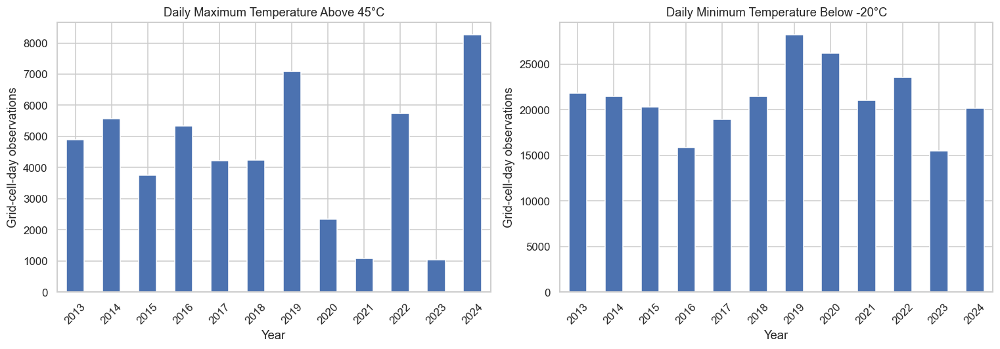


Extreme investigation saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_temperature_extreme_investigation.json

Temperature extreme investigation completed.


In [11]:

# ============================================================
# WI-02 | CELL 10: TEMPERATURE EXTREME INVESTIGATION
# ============================================================

HOT_THRESHOLD = 45.0
COLD_THRESHOLD = -20.0

# ------------------------------------------------------------
# 1. Identify extreme observations
# ------------------------------------------------------------

hot_extremes = weather[
    weather[TMAX_COL] > HOT_THRESHOLD
].copy()

cold_extremes = weather[
    weather[TMIN_COL] < COLD_THRESHOLD
].copy()

print("=" * 65)
print("TEMPERATURE EXTREME INVESTIGATION")
print("=" * 65)

print("Maximum temperature observations above 45°C:",
      f"{len(hot_extremes):,}")

print("Minimum temperature observations below -20°C:",
      f"{len(cold_extremes):,}")

# ------------------------------------------------------------
# 2. Temporal distribution of extremes
# ------------------------------------------------------------

hot_by_year = (
    hot_extremes.groupby("year")
    .size()
    .rename("observations_above_45C")
)

cold_by_year = (
    cold_extremes.groupby("year")
    .size()
    .rename("observations_below_minus_20C")
)

extremes_by_year = pd.concat(
    [hot_by_year, cold_by_year],
    axis=1
).fillna(0).astype(int)

print("\nEXTREME OBSERVATIONS BY YEAR")
display(extremes_by_year)

# Monthly distribution
hot_extremes["month"] = hot_extremes["date"].dt.month
cold_extremes["month"] = cold_extremes["date"].dt.month

hot_by_month = (
    hot_extremes.groupby("month")
    .size()
    .rename("observations_above_45C")
)

cold_by_month = (
    cold_extremes.groupby("month")
    .size()
    .rename("observations_below_minus_20C")
)

extremes_by_month = pd.concat(
    [hot_by_month, cold_by_month],
    axis=1
).fillna(0).astype(int)

print("\nEXTREME OBSERVATIONS BY MONTH")
display(extremes_by_month)

# ------------------------------------------------------------
# 3. Geographic concentration of extremes
# ------------------------------------------------------------

hot_by_cell = (
    hot_extremes.groupby("cell_id")
    .agg(
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        extreme_days=(TMAX_COL, "size"),
        maximum_observed_tmax=(TMAX_COL, "max")
    )
    .reset_index()
    .sort_values("extreme_days", ascending=False)
)

cold_by_cell = (
    cold_extremes.groupby("cell_id")
    .agg(
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        extreme_days=(TMIN_COL, "size"),
        minimum_observed_tmin=(TMIN_COL, "min")
    )
    .reset_index()
    .sort_values("extreme_days", ascending=False)
)

print("\nTOP 15 CELLS BY HOT EXTREME OBSERVATION COUNT")
display(hot_by_cell.head(15).round(3))

print("\nTOP 15 CELLS BY COLD EXTREME OBSERVATION COUNT")
display(cold_by_cell.head(15).round(3))

# ------------------------------------------------------------
# 4. Consecutive-day persistence
# ------------------------------------------------------------

def summarize_extreme_runs(extreme_df, variable, threshold, condition):
    """
    Summarize consecutive extreme-day runs per grid cell.
    A run is counted separately for each cell.
    """

    if extreme_df.empty:
        return pd.DataFrame(), pd.DataFrame()

    ordered = extreme_df.sort_values(
        ["cell_id", "date"]
    ).copy()

    day_gap = (
        ordered.groupby("cell_id")["date"]
        .diff()
        .dt.days
    )

    ordered["new_run"] = (
        day_gap.isna() | day_gap.ne(1)
    )

    ordered["run_id"] = (
        ordered.groupby("cell_id")["new_run"]
        .cumsum()
    )

    runs = (
        ordered.groupby(["cell_id", "run_id"])
        .agg(
            start_date=("date", "min"),
            end_date=("date", "max"),
            duration_days=("date", "size"),
            extreme_value=(variable, "max" if condition == "above" else "min")
        )
        .reset_index()
    )

    summary = pd.Series({
        "total_extreme_runs": len(runs),
        "single_day_runs": int((runs["duration_days"] == 1).sum()),
        "runs_2_days_or_more": int((runs["duration_days"] >= 2).sum()),
        "runs_3_days_or_more": int((runs["duration_days"] >= 3).sum()),
        "runs_5_days_or_more": int((runs["duration_days"] >= 5).sum()),
        "maximum_run_duration_days": int(runs["duration_days"].max()),
    }).to_frame("value")

    return runs, summary


hot_runs, hot_run_summary = summarize_extreme_runs(
    hot_extremes,
    TMAX_COL,
    HOT_THRESHOLD,
    "above"
)

cold_runs, cold_run_summary = summarize_extreme_runs(
    cold_extremes,
    TMIN_COL,
    COLD_THRESHOLD,
    "below"
)

print("\nHOT EXTREME RUN SUMMARY")
display(hot_run_summary)

print("\nCOLD EXTREME RUN SUMMARY")
display(cold_run_summary)

print("\nLONGEST HOT EXTREME RUNS")
display(
    hot_runs.nlargest(10, "duration_days")
    if not hot_runs.empty else hot_runs
)

print("\nLONGEST COLD EXTREME RUNS")
display(
    cold_runs.nlargest(10, "duration_days")
    if not cold_runs.empty else cold_runs
)

# ------------------------------------------------------------
# 5. Inspect nearby grid cells and dates for the most extreme
#    observations.
# ------------------------------------------------------------

def inspect_extreme_neighborhood(
    extreme_df,
    variable,
    mode,
    neighborhood_degrees=0.7,
    date_window_days=1,
    top_n=5
):
    """
    For each selected extreme record, inspect nearby grid cells
    within a coordinate window and nearby dates.

    This is a consistency check, not independent validation:
    all observations come from the same underlying archive.
    """

    if extreme_df.empty:
        return pd.DataFrame()

    if mode == "hot":
        candidates = extreme_df.nlargest(top_n, variable)
    else:
        candidates = extreme_df.nsmallest(top_n, variable)

    records = []

    for _, candidate in candidates.iterrows():

        date_mask = (
            weather["date"].between(
                candidate["date"] - pd.Timedelta(days=date_window_days),
                candidate["date"] + pd.Timedelta(days=date_window_days)
            )
        )

        spatial_mask = (
            (weather["latitude"] - candidate["latitude"]).abs()
            <= neighborhood_degrees
        ) & (
            (weather["longitude"] - candidate["longitude"]).abs()
            <= neighborhood_degrees
        )

        neighborhood = weather[
            date_mask & spatial_mask
        ].copy()

        same_day = neighborhood[
            neighborhood["date"] == candidate["date"]
        ]

        records.append({
            "extreme_cell_id": candidate["cell_id"],
            "extreme_date": candidate["date"].date().isoformat(),
            "extreme_latitude": candidate["latitude"],
            "extreme_longitude": candidate["longitude"],
            "extreme_value_c": candidate[variable],
            "neighbor_observation_count": len(same_day),
            "same_day_neighbor_median_c": (
                same_day[variable].median()
                if not same_day.empty else np.nan
            ),
            "same_day_neighbor_min_c": (
                same_day[variable].min()
                if not same_day.empty else np.nan
            ),
            "same_day_neighbor_max_c": (
                same_day[variable].max()
                if not same_day.empty else np.nan
            ),
            "three_day_neighborhood_median_c": (
                neighborhood[variable].median()
                if not neighborhood.empty else np.nan
            ),
            "three_day_neighborhood_min_c": (
                neighborhood[variable].min()
                if not neighborhood.empty else np.nan
            ),
            "three_day_neighborhood_max_c": (
                neighborhood[variable].max()
                if not neighborhood.empty else np.nan
            )
        })

    return pd.DataFrame(records)


hot_neighborhood = inspect_extreme_neighborhood(
    hot_extremes,
    TMAX_COL,
    mode="hot"
)

cold_neighborhood = inspect_extreme_neighborhood(
    cold_extremes,
    TMIN_COL,
    mode="cold"
)

print("\nHOT EXTREME NEIGHBORHOOD CHECK")
display(hot_neighborhood.round(3))

print("\nCOLD EXTREME NEIGHBORHOOD CHECK")
display(cold_neighborhood.round(3))

# ------------------------------------------------------------
# 6. Visualize annual extreme counts
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

extremes_by_year["observations_above_45C"].plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Daily Maximum Temperature Above 45°C")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Grid-cell-day observations")
axes[0].tick_params(axis="x", rotation=45)

extremes_by_year["observations_below_minus_20C"].plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Daily Minimum Temperature Below -20°C")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Grid-cell-day observations")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save investigation results
# ------------------------------------------------------------

extreme_findings = {
    "thresholds": {
        "T2M_MAX_above_C": HOT_THRESHOLD,
        "T2M_MIN_below_C": COLD_THRESHOLD
    },
    "total_observations": {
        "hot": len(hot_extremes),
        "cold": len(cold_extremes)
    },
    "annual_counts": (
        extremes_by_year.to_dict(orient="index")
    ),
    "monthly_counts": (
        extremes_by_month.to_dict(orient="index")
    ),
    "hot_run_summary": (
        hot_run_summary["value"].to_dict()
        if not hot_run_summary.empty else {}
    ),
    "cold_run_summary": (
        cold_run_summary["value"].to_dict()
        if not cold_run_summary.empty else {}
    ),
    "interpretation_note": (
        "Extreme observations are retained. "
        "Spatial and temporal consistency checks use the same "
        "archive and are not independent source validation."
    )
}

extreme_findings_path = (
    OUTPUT_DIR / "WI_02_temperature_extreme_investigation.json"
)

with open(
    extreme_findings_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        extreme_findings,
        file,
        indent=2,
        ensure_ascii=False,
        default=str
    )

print("\nExtreme investigation saved to:")
print(extreme_findings_path)

print("\nTemperature extreme investigation completed.")


In [13]:

# ============================================================
# WI-02 | CELL 11: EXTREME-TEMPERATURE PROVENANCE AND QC AUDIT
# ============================================================

# Select only records that meet either extreme threshold.
# Arrow filtering avoids loading all provenance columns for
# the full 11-million-row dataset.

EXTREME_PROVENANCE_COLUMNS = [
    "cell_id",
    "date",
    "latitude",
    "longitude",
    TMAX_COL,
    TMIN_COL,
    "T2M_MAX_source_region_id",
    "T2M_MAX_source_tags",
    "T2M_MIN_source_region_id",
    "T2M_MIN_source_tags",
    "qc_pass",
    "qc_missing",
    "qc_sentinel",
    "qc_non_finite",
    "qc_negative_precipitation",
    "qc_tmin_gt_tmax"
]

extreme_filter = (
    (ds.field(TMAX_COL) > HOT_THRESHOLD)
    | (ds.field(TMIN_COL) < COLD_THRESHOLD)
)

extreme_provenance = weather_dataset.to_table(
    columns=EXTREME_PROVENANCE_COLUMNS,
    filter=extreme_filter
).to_pandas()

# Separate hot and cold subsets
hot_provenance = extreme_provenance[
    extreme_provenance[TMAX_COL] > HOT_THRESHOLD
].copy()

cold_provenance = extreme_provenance[
    extreme_provenance[TMIN_COL] < COLD_THRESHOLD
].copy()

print("=" * 65)
print("EXTREME-TEMPERATURE PROVENANCE AUDIT")
print("=" * 65)

print("Retrieved extreme records:", f"{len(extreme_provenance):,}")
print("Hot extreme records:", f"{len(hot_provenance):,}")
print("Cold extreme records:", f"{len(cold_provenance):,}")

# ------------------------------------------------------------
# 1. Source tags and source-region distribution
# ------------------------------------------------------------

print("\nHOT EXTREMES: SOURCE TAGS")
display(
    hot_provenance["T2M_MAX_source_tags"]
    .value_counts(dropna=False)
    .to_frame("observation_count")
)

print("\nHOT EXTREMES: SOURCE REGION IDs")
display(
    hot_provenance["T2M_MAX_source_region_id"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("observation_count")
)

print("\nCOLD EXTREMES: SOURCE TAGS")
display(
    cold_provenance["T2M_MIN_source_tags"]
    .value_counts(dropna=False)
    .to_frame("observation_count")
)

print("\nCOLD EXTREMES: SOURCE REGION IDs")
display(
    cold_provenance["T2M_MIN_source_region_id"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("observation_count")
)

# ------------------------------------------------------------
# 2. QC flag distribution
# ------------------------------------------------------------

QC_COLUMNS = [
    "qc_pass",
    "qc_missing",
    "qc_sentinel",
    "qc_non_finite",
    "qc_negative_precipitation",
    "qc_tmin_gt_tmax"
]

hot_qc_summary = hot_provenance[QC_COLUMNS].sum().to_frame(
    "flagged_observations"
)

cold_qc_summary = cold_provenance[QC_COLUMNS].sum().to_frame(
    "flagged_observations"
)

print("\nHOT EXTREMES: QC FLAG COUNTS")
display(hot_qc_summary)

print("\nCOLD EXTREMES: QC FLAG COUNTS")
display(cold_qc_summary)

print("\nQC PASS RATE")
print(
    "Hot:",
    f"{hot_provenance['qc_pass'].mean() * 100:.3f}%"
)
print(
    "Cold:",
    f"{cold_provenance['qc_pass'].mean() * 100:.3f}%"
)

# ------------------------------------------------------------
# 3. Provenance of the most extreme individual observations
# ------------------------------------------------------------

print("\nTOP 10 HOTTEST OBSERVATIONS WITH PROVENANCE")
display(
    hot_provenance.nlargest(10, TMAX_COL)[
        [
            "cell_id", "date", "latitude", "longitude",
            TMAX_COL, "T2M_MAX_source_region_id",
            "T2M_MAX_source_tags", "qc_pass"
        ]
    ]
)

print("\nTOP 10 COLDEST OBSERVATIONS WITH PROVENANCE")
display(
    cold_provenance.nsmallest(10, TMIN_COL)[
        [
            "cell_id", "date", "latitude", "longitude",
            TMIN_COL, "T2M_MIN_source_region_id",
            "T2M_MIN_source_tags", "qc_pass"
        ]
    ]
)


# ------------------------------------------------------------
# 4. Provenance for longest extreme runs
# ------------------------------------------------------------

def attach_extreme_run_provenance(
    runs,
    provenance,
    region_column,
    tags_column,
    count=10
):
    if runs.empty:
        return pd.DataFrame()

    longest = runs.nlargest(
        count, "duration_days"
    ).copy()

    provenance_lookup = provenance[
        [
            "cell_id",
            "date",
            region_column,
            tags_column,
            "qc_pass"
        ]
    ].copy()

    # Normalize both merge keys to datetime64[ns].
    longest["start_date"] = pd.to_datetime(
        longest["start_date"],
        errors="raise"
    )

    provenance_lookup["date"] = pd.to_datetime(
        provenance_lookup["date"],
        errors="raise"
    )

    provenance_lookup = provenance_lookup.drop_duplicates(
        ["cell_id", "date"]
    )

    result = longest.merge(
        provenance_lookup,
        left_on=["cell_id", "start_date"],
        right_on=["cell_id", "date"],
        how="left",
        validate="many_to_one"
    )

    return result.drop(columns=["date"])


hot_run_provenance = attach_extreme_run_provenance(
    hot_runs,
    hot_provenance,
    "T2M_MAX_source_region_id",
    "T2M_MAX_source_tags"
)

cold_run_provenance = attach_extreme_run_provenance(
    cold_runs,
    cold_provenance,
    "T2M_MIN_source_region_id",
    "T2M_MIN_source_tags"
)

print("\nLONGEST HOT RUNS WITH PROVENANCE")
display(hot_run_provenance)

print("\nLONGEST COLD RUNS WITH PROVENANCE")
display(cold_run_provenance)

# ------------------------------------------------------------
# 5. Save audit findings
# ------------------------------------------------------------

def source_counts(series):
    return {
        str(key): int(value)
        for key, value in series.value_counts(
            dropna=False
        ).items()
    }


extreme_provenance_findings = {
    "thresholds": {
        "T2M_MAX_above_C": HOT_THRESHOLD,
        "T2M_MIN_below_C": COLD_THRESHOLD
    },
    "record_counts": {
        "all_extreme_records": int(len(extreme_provenance)),
        "hot_records": int(len(hot_provenance)),
        "cold_records": int(len(cold_provenance))
    },
    "source_tags": {
        "hot": source_counts(
            hot_provenance["T2M_MAX_source_tags"]
        ),
        "cold": source_counts(
            cold_provenance["T2M_MIN_source_tags"]
        )
    },
    "source_region_ids": {
        "hot": source_counts(
            hot_provenance["T2M_MAX_source_region_id"]
        ),
        "cold": source_counts(
            cold_provenance["T2M_MIN_source_region_id"]
        )
    },
    "qc_flag_counts": {
        "hot": {
            col: int(hot_provenance[col].sum())
            for col in QC_COLUMNS
        },
        "cold": {
            col: int(cold_provenance[col].sum())
            for col in QC_COLUMNS
        }
    },
    "qc_pass_rates": {
        "hot": float(hot_provenance["qc_pass"].mean()),
        "cold": float(cold_provenance["qc_pass"].mean())
    },
    "interpretation_note": (
        "QC pass indicates compliance with the stored dataset "
        "QC rules only. It does not establish physical accuracy "
        "of extreme temperatures. Source metadata and internal "
        "spatial consistency are not independent validation."
    )
}

provenance_path = (
    OUTPUT_DIR / "WI_02_temperature_extreme_provenance.json"
)

with open(
    provenance_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        extreme_provenance_findings,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nExtreme-temperature provenance audit saved to:")
print(provenance_path)

print("\nProvenance and QC audit completed.")


EXTREME-TEMPERATURE PROVENANCE AUDIT
Retrieved extreme records: 308,153
Hot extreme records: 53,554
Cold extreme records: 254,599

HOT EXTREMES: SOURCE TAGS


,observation_count
T2M_MAX_source_tags,
"[""MERRA2"",""POWER""]",53554



HOT EXTREMES: SOURCE REGION IDs


,observation_count
T2M_MAX_source_region_id,
R036,11684
R031,6006
R037,5054
R032,4934
R038,4342
R043,3817
R029,3352
R024,3341
R030,2883



COLD EXTREMES: SOURCE TAGS


,observation_count
T2M_MIN_source_tags,
"[""MERRA2"",""POWER""]",254599


... (11 outputs left out)

,cell_id,run_id,start_date,end_date,duration_days,extreme_value,T2M_MAX_source_region_id,T2M_MAX_source_tags,qc_pass
0,cell_1982,99,2024-05-15,2024-06-05,22,51.30,R036,"[""MERRA2"",""POWER""]",True
1,cell_1983,89,2024-05-15,2024-06-05,22,50.20,R036,"[""MERRA2"",""POWER""]",True
2,cell_2027,113,2024-05-15,2024-06-05,22,50.92,R036,"[""MERRA2"",""POWER""]",True
3,cell_2028,110,2024-05-15,2024-06-05,22,49.92,R036,"[""MERRA2"",""POWER""]",True
4,cell_2073,114,2024-05-15,2024-06-05,22,49.73,R036,"[""MERRA2"",""POWER""]",True
5,cell_2074,103,2024-05-15,2024-06-05,22,49.34,R036,"[""MERRA2"",""POWER""]",True
6,cell_2119,93,2024-05-15,2024-06-05,22,48.57,R036,"[""MERRA2"",""POWER""]",True
7,cell_2120,86,2024-05-15,2024-06-05,22,48.96,R036,"[""MERRA2"",""POWER""]",True
8,cell_2121,70,2024-05-15,2024-06-05,22,49.29,R036,"[""MERRA2"",""POWER""]",True
9,cell_2165,74,2024-05-15,2024-06-05,22,48.94,R043,"[""MERRA2"",""POWER""]",True



LONGEST COLD RUNS WITH PROVENANCE


,cell_id,run_id,start_date,end_date,duration_days,extreme_value,T2M_MIN_source_region_id,T2M_MIN_source_tags,qc_pass
0,cell_2490,51,2018-11-03,2019-04-03,152,-39.29,R052,"[""MERRA2"",""POWER""]",True
1,cell_2490,55,2019-11-23,2020-04-12,142,-39.67,R052,"[""MERRA2"",""POWER""]",True
2,cell_2399,62,2018-11-13,2019-03-27,135,-40.01,R052,"[""MERRA2"",""POWER""]",True
3,cell_2354,66,2020-11-16,2021-03-21,126,-36.80,R052,"[""MERRA2"",""POWER""]",True
4,cell_2354,61,2019-11-23,2020-03-23,122,-37.68,R052,"[""MERRA2"",""POWER""]",True
5,cell_2445,57,2019-11-23,2020-03-23,122,-41.20,R052,"[""MERRA2"",""POWER""]",True
6,cell_2491,49,2019-11-23,2020-03-23,122,-37.77,R052,"[""MERRA2"",""POWER""]",True
7,cell_2181,67,2019-12-13,2020-04-11,121,-39.50,R046,"[""MERRA2"",""POWER""]",True
8,cell_2226,60,2019-12-14,2020-04-11,120,-40.08,R046,"[""MERRA2"",""POWER""]",True
9,cell_2354,57,2018-11-28,2019-03-27,120,-37.40,R052,"[""MERRA2"",""POWER""]",True



Extreme-temperature provenance audit saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_temperature_extreme_provenance.json

Provenance and QC audit completed.


PEARSON CORRELATION MATRIX


,PRECTOTCORR,T2M_MAX,T2M_MIN,TEMP_RANGE
PRECTOTCORR,1.000,0.071,0.175,-0.248
T2M_MAX,0.071,1.000,0.884,-0.159
T2M_MIN,0.175,0.884,1.000,-0.602
TEMP_RANGE,-0.248,-0.159,-0.602,1.000



SPEARMAN CORRELATION MATRIX


,PRECTOTCORR,T2M_MAX,T2M_MIN,TEMP_RANGE
PRECTOTCORR,1.000,0.096,0.410,-0.493
T2M_MAX,0.096,1.000,0.540,0.030
T2M_MIN,0.410,0.540,1.000,-0.736
TEMP_RANGE,-0.493,0.030,-0.736,1.000



WET-DAY VERSUS DRY-DAY TEMPERATURE SUMMARY


,observation_count,mean_tmax_c,median_tmax_c,mean_tmin_c,median_tmin_c,mean_temp_range_c,median_temp_range_c
rainfall_category,,,,,,,
Dry,3831188,24.119,27.49,11.864,15.71,12.256,13.94
Wet,7213972,26.889,28.76,21.160,26.37,5.729,4.44



SEASONAL WET-DAY VERSUS DRY-DAY SUMMARY


,calendar_season,rainfall_category,observation_count,mean_tmax_c,mean_tmin_c,mean_temp_range_c,mean_rainfall_mm_day
0,Monsoon (Jun-Sep),Dry,287157,30.588,17.334,13.254,0.000
1,Monsoon (Jun-Sep),Wet,3402123,27.992,22.237,5.754,7.955
2,Post-monsoon (Oct-Nov),Dry,798195,22.242,10.101,12.140,0.000
3,Post-monsoon (Oct-Nov),Wet,1046445,26.399,22.166,4.233,5.299
4,Pre-monsoon (Mar-May),Dry,1027535,29.540,16.759,12.781,0.000
5,Pre-monsoon (Mar-May),Wet,1754545,27.335,20.385,6.950,3.172
6,Winter (Dec-Feb),Dry,1718301,20.669,8.841,11.828,0.000
7,Winter (Dec-Feb),Wet,1010859,22.913,17.841,5.072,2.553



TEMPERATURE SUMMARY BY RAINFALL INTENSITY


,observation_count,mean_tmax_c,mean_tmin_c,mean_temp_range_c,mean_rainfall_mm_day,percentage_of_observations
rainfall_intensity,,,,,,
Dry (0 mm),3831188,24.119,11.864,12.256,0.000,34.687
Light (>0–2.5 mm),4004556,26.210,19.407,6.803,0.684,36.256
Moderate (>2.5–7.5 mm),1629754,27.402,22.453,4.949,4.564,14.755
Heavy (>7.5–35 mm),1422187,28.056,24.138,3.918,14.998,12.876
Very heavy (>35 mm),157475,28.305,25.462,2.843,58.739,1.426


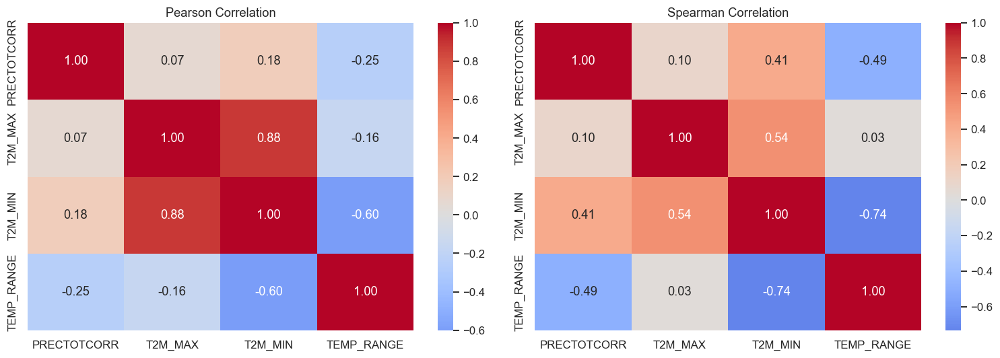

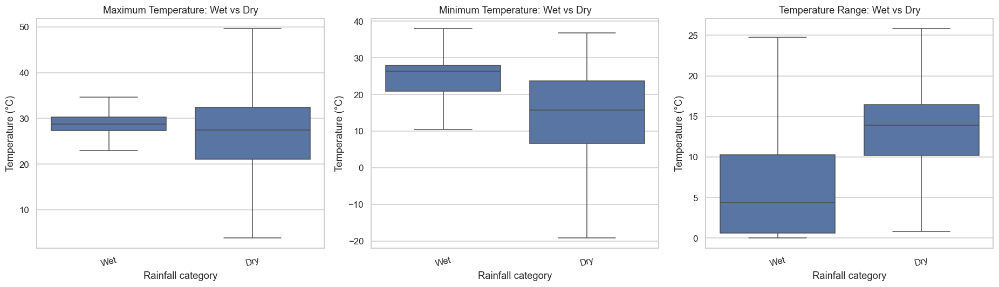

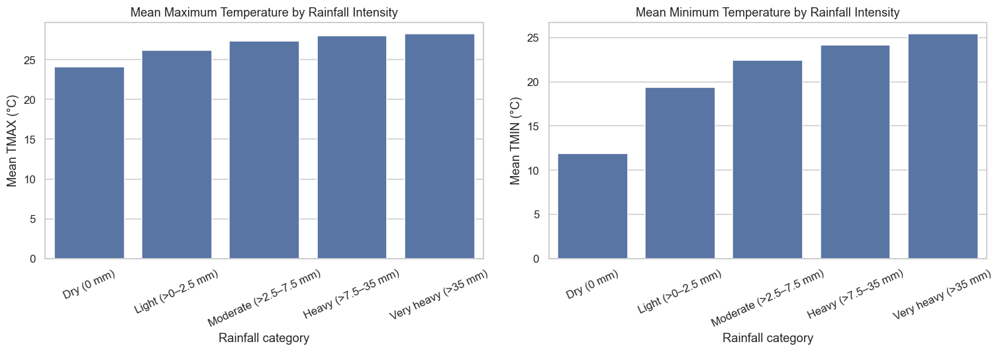


Weather relationship findings saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_weather_variable_relationships.json

Weather variable relationship analysis completed.


In [14]:

# ============================================================
# WI-02 | CELL 12: WEATHER VARIABLE RELATIONSHIPS
# ============================================================

# ------------------------------------------------------------
# 1. Prepare analysis variables
# ------------------------------------------------------------

RELATIONSHIP_COLUMNS = [
    "PRECTOTCORR",
    TMAX_COL,
    TMIN_COL,
    "TEMP_RANGE"
]

relationship_data = weather[
    RELATIONSHIP_COLUMNS + ["calendar_season"]
].copy()

relationship_data["rainfall_category"] = np.where(
    relationship_data["PRECTOTCORR"] > 0,
    "Wet",
    "Dry"
)

# ------------------------------------------------------------
# 2. Overall correlation analysis
# ------------------------------------------------------------

pearson_correlation = relationship_data[
    RELATIONSHIP_COLUMNS
].corr(method="pearson")

spearman_correlation = relationship_data[
    RELATIONSHIP_COLUMNS
].corr(method="spearman")

print("=" * 65)
print("PEARSON CORRELATION MATRIX")
print("=" * 65)
display(pearson_correlation.round(3))

print("\nSPEARMAN CORRELATION MATRIX")
display(spearman_correlation.round(3))

# ------------------------------------------------------------
# 3. Wet-day versus dry-day temperature comparison
# ------------------------------------------------------------

wet_dry_temperature = (
    relationship_data.groupby("rainfall_category")
    .agg(
        observation_count=(TMAX_COL, "size"),
        mean_tmax_c=(TMAX_COL, "mean"),
        median_tmax_c=(TMAX_COL, "median"),
        mean_tmin_c=(TMIN_COL, "mean"),
        median_tmin_c=(TMIN_COL, "median"),
        mean_temp_range_c=("TEMP_RANGE", "mean"),
        median_temp_range_c=("TEMP_RANGE", "median")
    )
)

print("\nWET-DAY VERSUS DRY-DAY TEMPERATURE SUMMARY")
display(wet_dry_temperature.round(3))

# ------------------------------------------------------------
# 4. Seasonal wet-day versus dry-day comparison
# ------------------------------------------------------------

seasonal_wet_dry = (
    relationship_data.groupby(
        ["calendar_season", "rainfall_category"],
        observed=True
    )
    .agg(
        observation_count=(TMAX_COL, "size"),
        mean_tmax_c=(TMAX_COL, "mean"),
        mean_tmin_c=(TMIN_COL, "mean"),
        mean_temp_range_c=("TEMP_RANGE", "mean"),
        mean_rainfall_mm_day=("PRECTOTCORR", "mean")
    )
    .reset_index()
)

print("\nSEASONAL WET-DAY VERSUS DRY-DAY SUMMARY")
display(
    seasonal_wet_dry.round(3)
)

# ------------------------------------------------------------
# 5. Rainfall intensity categories
# ------------------------------------------------------------

def classify_rainfall(value):
    if value == 0:
        return "Dry (0 mm)"
    elif value <= 2.5:
        return "Light (>0–2.5 mm)"
    elif value <= 7.5:
        return "Moderate (>2.5–7.5 mm)"
    elif value <= 35:
        return "Heavy (>7.5–35 mm)"
    else:
        return "Very heavy (>35 mm)"


rainfall_category_order = [
    "Dry (0 mm)",
    "Light (>0–2.5 mm)",
    "Moderate (>2.5–7.5 mm)",
    "Heavy (>7.5–35 mm)",
    "Very heavy (>35 mm)"
]

relationship_data["rainfall_intensity"] = (
    relationship_data["PRECTOTCORR"]
    .map(classify_rainfall)
)

intensity_summary = (
    relationship_data.groupby(
        "rainfall_intensity",
        observed=True
    )
    .agg(
        observation_count=(TMAX_COL, "size"),
        mean_tmax_c=(TMAX_COL, "mean"),
        mean_tmin_c=(TMIN_COL, "mean"),
        mean_temp_range_c=("TEMP_RANGE", "mean"),
        mean_rainfall_mm_day=("PRECTOTCORR", "mean")
    )
    .reindex(rainfall_category_order)
)

intensity_summary["percentage_of_observations"] = (
    intensity_summary["observation_count"]
    / len(relationship_data) * 100
)

print("\nTEMPERATURE SUMMARY BY RAINFALL INTENSITY")
display(intensity_summary.round(3))

# ------------------------------------------------------------
# 6. Visualizations
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    pearson_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[0]
)
axes[0].set_title("Pearson Correlation")

sns.heatmap(
    spearman_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)
axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

# Temperature distributions by wet/dry category
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, variable, title in zip(
    axes,
    [TMAX_COL, TMIN_COL, "TEMP_RANGE"],
    [
        "Maximum Temperature",
        "Minimum Temperature",
        "Temperature Range"
    ]
):
    sns.boxplot(
        data=relationship_data,
        x="rainfall_category",
        y=variable,
        ax=ax,
        showfliers=False
    )
    ax.set_title(f"{title}: Wet vs Dry")
    ax.set_xlabel("Rainfall category")
    ax.set_ylabel("Temperature (°C)")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# Mean temperature by rainfall intensity
intensity_plot = intensity_summary.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=intensity_plot,
    x="rainfall_intensity",
    y="mean_tmax_c",
    order=rainfall_category_order,
    ax=axes[0]
)
axes[0].set_title("Mean Maximum Temperature by Rainfall Intensity")
axes[0].set_xlabel("Rainfall category")
axes[0].set_ylabel("Mean TMAX (°C)")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(
    data=intensity_plot,
    x="rainfall_intensity",
    y="mean_tmin_c",
    order=rainfall_category_order,
    ax=axes[1]
)
axes[1].set_title("Mean Minimum Temperature by Rainfall Intensity")
axes[1].set_xlabel("Rainfall category")
axes[1].set_ylabel("Mean TMIN (°C)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save relationship findings
# ------------------------------------------------------------

relationship_findings = {
    "pearson_correlation": (
        pearson_correlation.round(4).to_dict()
    ),
    "spearman_correlation": (
        spearman_correlation.round(4).to_dict()
    ),
    "wet_dry_temperature_summary": (
        wet_dry_temperature.round(4).to_dict(orient="index")
    ),
    "seasonal_wet_dry_summary": (
        seasonal_wet_dry.round(4).to_dict(orient="records")
    ),
    "rainfall_intensity_summary": (
        intensity_summary.round(4).to_dict(orient="index")
    ),
    "rainfall_intensity_thresholds_mm_day": {
        "dry": "0",
        "light": ">0 to 2.5",
        "moderate": ">2.5 to 7.5",
        "heavy": ">7.5 to 35",
        "very_heavy": ">35"
    },
    "interpretation_note": (
        "Descriptive associations only. "
        "Pooled correlations may be confounded by season, "
        "geography and temporal structure. "
        "Rainfall categories are analytical bins, not "
        "agricultural hazard classifications."
    )
}

relationship_path = (
    OUTPUT_DIR / "WI_02_weather_variable_relationships.json"
)

with open(
    relationship_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        relationship_findings,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nWeather relationship findings saved to:")
print(relationship_path)

print("\nWeather variable relationship analysis completed.")


GRID-CELL / CALENDAR-MONTH ANOMALY SUMMARY


,PRECTOTCORR_ANOMALY,T2M_MAX_ANOMALY,T2M_MIN_ANOMALY,TEMP_RANGE_ANOMALY
count,1.104516e+07,1.104516e+07,1.104516e+07,1.104516e+07
mean,-0.000000e+00,-0.000000e+00,0.000000e+00,0.000000e+00
std,8.252000e+00,2.146000e+00,1.838000e+00,1.778000e+00
min,-5.672400e+01,-2.017000e+01,-2.172800e+01,-1.395900e+01
25%,-2.240000e+00,-8.270000e-01,-7.310000e-01,-5.330000e-01
50%,-4.970000e-01,2.700000e-02,3.600000e-02,-2.800000e-02
75%,-5.100000e-02,8.810000e-01,7.710000e-01,7.140000e-01
max,9.820950e+02,1.459900e+01,1.378100e+01,1.527200e+01



PEARSON CORRELATION OF ANOMALIES


,PRECTOTCORR_ANOMALY,T2M_MAX_ANOMALY,T2M_MIN_ANOMALY,TEMP_RANGE_ANOMALY
PRECTOTCORR_ANOMALY,1.000,-0.136,-0.002,-0.162
T2M_MAX_ANOMALY,-0.136,1.000,0.611,0.575
T2M_MIN_ANOMALY,-0.002,0.611,1.000,-0.296
TEMP_RANGE_ANOMALY,-0.162,0.575,-0.296,1.000



SPEARMAN CORRELATION OF ANOMALIES


,PRECTOTCORR_ANOMALY,T2M_MAX_ANOMALY,T2M_MIN_ANOMALY,TEMP_RANGE_ANOMALY
PRECTOTCORR_ANOMALY,1.000,-0.164,0.005,-0.186
T2M_MAX_ANOMALY,-0.164,1.000,0.579,0.496
T2M_MIN_ANOMALY,0.005,0.579,1.000,-0.266
TEMP_RANGE_ANOMALY,-0.186,0.496,-0.266,1.000


... (8 outputs left out)


Monsoon (Jun-Sep): SPEARMAN ANOMALY CORRELATION


,PRECTOTCORR_ANOMALY,T2M_MAX_ANOMALY,T2M_MIN_ANOMALY,TEMP_RANGE_ANOMALY
PRECTOTCORR_ANOMALY,1.000,-0.257,-0.052,-0.250
T2M_MAX_ANOMALY,-0.257,1.000,0.511,0.674
T2M_MIN_ANOMALY,-0.052,0.511,1.000,-0.142
TEMP_RANGE_ANOMALY,-0.250,0.674,-0.142,1.000



Post-monsoon (Oct-Nov): SPEARMAN ANOMALY CORRELATION


,PRECTOTCORR_ANOMALY,T2M_MAX_ANOMALY,T2M_MIN_ANOMALY,TEMP_RANGE_ANOMALY
PRECTOTCORR_ANOMALY,1.000,-0.106,0.074,-0.156
T2M_MAX_ANOMALY,-0.106,1.000,0.553,0.351
T2M_MIN_ANOMALY,0.074,0.553,1.000,-0.448
TEMP_RANGE_ANOMALY,-0.156,0.351,-0.448,1.000


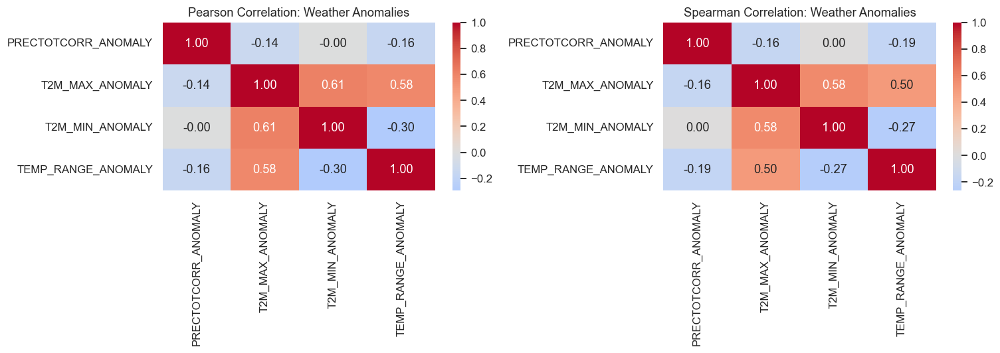


Deconfounded relationship findings saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_deconfounded_weather_relationships.json

Deconfounded weather relationship analysis completed.


In [15]:

# ============================================================
# WI-02 | CELL 13: DECONFOUNDED WEATHER RELATIONSHIPS
# ============================================================

# ------------------------------------------------------------
# 1. Prepare grid-cell/month reference climatology
# ------------------------------------------------------------

analysis_columns = [
    "PRECTOTCORR",
    TMAX_COL,
    TMIN_COL,
    "TEMP_RANGE"
]

weather["calendar_month"] = weather["date"].dt.month

# Historical monthly climatology for each grid cell.
# This is descriptive and uses the full 2013–2024 archive.
cell_month_climatology = (
    weather.groupby(
        ["cell_id", "calendar_month"],
        observed=True
    )[analysis_columns]
    .transform("mean")
)

# Calculate deviations from each cell's own monthly average.
for column in analysis_columns:
    weather[f"{column}_ANOMALY"] = (
        weather[column] - cell_month_climatology[column]
    )

anomaly_columns = [
    f"{column}_ANOMALY"
    for column in analysis_columns
]

print("=" * 65)
print("GRID-CELL / CALENDAR-MONTH ANOMALY SUMMARY")
print("=" * 65)

display(
    weather[anomaly_columns]
    .describe()
    .round(3)
)

# ------------------------------------------------------------
# 2. Correlations using anomalies
# ------------------------------------------------------------

anomaly_correlation_pearson = (
    weather[anomaly_columns]
    .corr(method="pearson")
)

anomaly_correlation_spearman = (
    weather[anomaly_columns]
    .corr(method="spearman")
)

print("\nPEARSON CORRELATION OF ANOMALIES")
display(anomaly_correlation_pearson.round(3))

print("\nSPEARMAN CORRELATION OF ANOMALIES")
display(anomaly_correlation_spearman.round(3))

# ------------------------------------------------------------
# 3. Wet/dry comparisons using temperature anomalies
# ------------------------------------------------------------

weather["rainfall_day_type"] = np.where(
    weather["PRECTOTCORR"] > 0,
    "Wet",
    "Dry"
)

wet_dry_anomaly_summary = (
    weather.groupby("rainfall_day_type")
    .agg(
        observation_count=("cell_id", "size"),
        mean_rainfall_anomaly=(
            "PRECTOTCORR_ANOMALY", "mean"
        ),
        mean_tmax_anomaly=(
            "T2M_MAX_ANOMALY", "mean"
        ),
        mean_tmin_anomaly=(
            "T2M_MIN_ANOMALY", "mean"
        ),
        mean_temp_range_anomaly=(
            "TEMP_RANGE_ANOMALY", "mean"
        )
    )
)

print("\nWET VERSUS DRY: MONTHLY-CLIMATOLOGY ANOMALIES")
display(wet_dry_anomaly_summary.round(4))

# ------------------------------------------------------------
# 4. Seasonal anomaly relationships
# ------------------------------------------------------------

seasonal_anomaly_summary = (
    weather.groupby(
        ["calendar_season", "rainfall_day_type"],
        observed=True
    )
    .agg(
        observation_count=("cell_id", "size"),
        mean_rainfall_anomaly=(
            "PRECTOTCORR_ANOMALY", "mean"
        ),
        mean_tmax_anomaly=(
            "T2M_MAX_ANOMALY", "mean"
        ),
        mean_tmin_anomaly=(
            "T2M_MIN_ANOMALY", "mean"
        ),
        mean_temp_range_anomaly=(
            "TEMP_RANGE_ANOMALY", "mean"
        )
    )
    .reset_index()
)

print("\nSEASONAL WET/DRY ANOMALY SUMMARY")
display(seasonal_anomaly_summary.round(4))

# ------------------------------------------------------------
# 5. Seasonal anomaly correlations
# ------------------------------------------------------------

seasonal_anomaly_correlations = {}

for season in season_order:
    subset = weather[
        weather["calendar_season"] == season
    ]

    corr = subset[anomaly_columns].corr(
        method="spearman"
    )

    seasonal_anomaly_correlations[season] = (
        corr.round(4).to_dict()
    )

    print(f"\n{season}: SPEARMAN ANOMALY CORRELATION")
    display(corr.round(3))

# ------------------------------------------------------------
# 6. Visualize anomaly relationships
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    anomaly_correlation_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[0]
)
axes[0].set_title("Pearson Correlation: Weather Anomalies")

sns.heatmap(
    anomaly_correlation_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)
axes[1].set_title("Spearman Correlation: Weather Anomalies")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save findings
# ------------------------------------------------------------

deconfounded_findings = {
    "reference_method": (
        "Grid-cell-specific calendar-month historical mean "
        "over the full 2013–2024 archive"
    ),
    "pearson_anomaly_correlations": (
        anomaly_correlation_pearson.round(4).to_dict()
    ),
    "spearman_anomaly_correlations": (
        anomaly_correlation_spearman.round(4).to_dict()
    ),
    "wet_dry_anomaly_summary": (
        wet_dry_anomaly_summary.round(4).to_dict(orient="index")
    ),
    "seasonal_wet_dry_anomaly_summary": (
        seasonal_anomaly_summary.round(4).to_dict(orient="records")
    ),
    "seasonal_spearman_anomaly_correlations": (
        seasonal_anomaly_correlations
    ),
    "limitations": [
        "Anomalies control grid-cell and calendar-month means, "
        "but do not establish causality.",
        "The full archive is used to calculate reference climatology; "
        "these anomalies are exploratory, not forecasting features.",
        "Serial dependence and year-specific effects remain.",
        "Rainfall is zero-heavy and strongly skewed."
    ]
}

deconfounded_path = (
    OUTPUT_DIR / "WI_02_deconfounded_weather_relationships.json"
)

with open(
    deconfounded_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        deconfounded_findings,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nDeconfounded relationship findings saved to:")
print(deconfounded_path)

print("\nDeconfounded weather relationship analysis completed.")


ANNUAL GRID-CELL AGGREGATION
Rows: 30,240
Unique grid cells: 2520
Years: [np.int16(2013), np.int16(2014), np.int16(2015), np.int16(2016), np.int16(2017), np.int16(2018), np.int16(2019), np.int16(2020), np.int16(2021), np.int16(2022), np.int16(2023), np.int16(2024)]

ANNUAL WEATHER SUMMARY


,mean_rainfall_mm_day,median_cell_mean_rainfall_mm_day,mean_wet_day_percentage,mean_tmax_c,mean_tmin_c,mean_temp_range_c,mean_cell_p95_rainfall_mm_day
year,,,,,,,
2013,3.9634,3.6569,62.7116,25.6677,17.6879,7.9798,17.3811
2014,3.2042,2.8917,61.7361,25.9156,17.7885,8.1271,14.6968
2015,3.4336,3.2002,65.3389,26.0114,17.8997,8.1117,15.8130
2016,3.5220,2.8723,62.3975,26.3914,18.2532,8.1382,16.3437
2017,3.8053,3.1346,64.9641,26.1050,18.0180,8.0869,16.9634
2018,3.4763,2.8924,63.5525,26.0225,17.8454,8.1771,15.9106
2019,3.7727,3.3115,67.1710,25.7434,17.8154,7.9280,17.9418
2020,4.0575,3.8662,68.5024,25.4505,17.6293,7.8212,18.1610
2021,3.9042,3.6061,68.2592,25.8282,17.9688,7.8594,17.3730



GRID-CELL TREND DISTRIBUTION: mean_rainfall_mm_day


,slope_per_year
count,2520.00000
mean,0.02383
std,0.09305
min,-0.47622
5%,-0.11415
25%,-0.02670
50%,0.02239
75%,0.06639
95%,0.17246
max,0.51568



GRID-CELL TREND DISTRIBUTION: wet_day_percentage


,slope_per_year
count,2520.00000
mean,0.45161
std,0.36702
min,-1.03838
5%,-0.09626
25%,0.17841
50%,0.42811
75%,0.68701
95%,1.09345
max,2.20113


... (2 outputs left out)


GRID-CELL TREND DISTRIBUTION: mean_tmin_c


,slope_per_year
count,2520.00000
mean,0.02568
std,0.03252
min,-0.23017
5%,-0.03034
25%,0.01810
50%,0.02946
75%,0.03904
95%,0.07101
max,0.14332



GRID-CELL TREND DISTRIBUTION: mean_temp_range_c


,slope_per_year
count,2520.00000
mean,-0.02509
std,0.04525
min,-0.17989
5%,-0.10315
25%,-0.05799
50%,-0.01021
75%,0.00481
95%,0.03447
max,0.14130


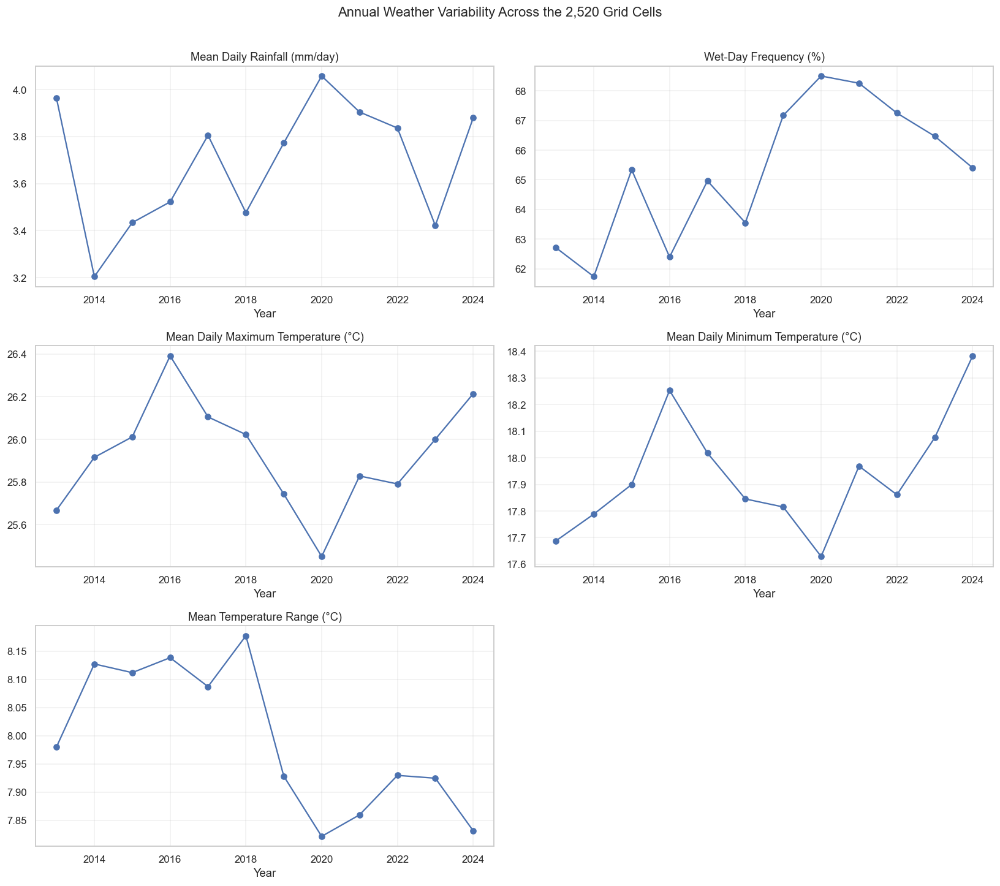


Saved annual summary:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_annual_weather_summary.csv

Saved grid-cell annual metrics:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_annual_weather_by_cell.csv

Saved trend findings:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_interannual_trend_findings.json

Interannual weather variability analysis completed.


In [16]:

# ============================================================
# WI-02 | CELL 14: INTERANNUAL VARIABILITY AND TREND SCREENING
# ============================================================

# ------------------------------------------------------------
# 1. Aggregate daily observations by grid cell and year
# ------------------------------------------------------------

annual_grid_metrics = (
    weather.groupby(
        ["cell_id", "year"],
        observed=True
    )
    .agg(
        mean_rainfall_mm_day=("PRECTOTCORR", "mean"),
        median_rainfall_mm_day=("PRECTOTCORR", "median"),
        p95_rainfall_mm_day=(
            "PRECTOTCORR",
            lambda values: values.quantile(0.95)
        ),
        wet_day_percentage=(
            "PRECTOTCORR",
            lambda values: (values > 0).mean() * 100
        ),
        mean_tmax_c=(TMAX_COL, "mean"),
        mean_tmin_c=(TMIN_COL, "mean"),
        mean_temp_range_c=("TEMP_RANGE", "mean")
    )
    .reset_index()
)

print("=" * 65)
print("ANNUAL GRID-CELL AGGREGATION")
print("=" * 65)
print("Rows:", f"{len(annual_grid_metrics):,}")
print("Unique grid cells:", annual_grid_metrics["cell_id"].nunique())
print("Years:", sorted(annual_grid_metrics["year"].unique()))

# ------------------------------------------------------------
# 2. Summarize annual metrics across grid cells
# ------------------------------------------------------------

annual_summary = (
    annual_grid_metrics.groupby("year")
    .agg(
        mean_rainfall_mm_day=(
            "mean_rainfall_mm_day", "mean"
        ),
        median_cell_mean_rainfall_mm_day=(
            "mean_rainfall_mm_day", "median"
        ),
        mean_wet_day_percentage=(
            "wet_day_percentage", "mean"
        ),
        mean_tmax_c=("mean_tmax_c", "mean"),
        mean_tmin_c=("mean_tmin_c", "mean"),
        mean_temp_range_c=("mean_temp_range_c", "mean"),
        mean_cell_p95_rainfall_mm_day=(
            "p95_rainfall_mm_day", "mean"
        )
    )
    .round(4)
)

print("\nANNUAL WEATHER SUMMARY")
display(annual_summary)

# ------------------------------------------------------------
# 3. Calculate simple linear trend slopes
# ------------------------------------------------------------

def calculate_linear_slope(series):
    valid = series.dropna()

    if len(valid) < 3:
        return np.nan

    years = valid.index.to_numpy(dtype=float)
    values = valid.to_numpy(dtype=float)

    return float(np.polyfit(years, values, 1)[0])


annual_metric_columns = [
    "mean_rainfall_mm_day",
    "wet_day_percentage",
    "mean_tmax_c",
    "mean_tmin_c",
    "mean_temp_range_c"
]

trend_results = {}

for metric in annual_metric_columns:
    annual_pivot = annual_grid_metrics.pivot(
        index="cell_id",
        columns="year",
        values=metric
    )

    cell_slopes = annual_pivot.apply(
        calculate_linear_slope,
        axis=1
    ).dropna()

    trend_results[metric] = {
        "grid_cells_with_estimated_slope": int(
            len(cell_slopes)
        ),
        "mean_slope_per_year": float(
            cell_slopes.mean()
        ),
        "median_slope_per_year": float(
            cell_slopes.median()
        ),
        "p05_slope_per_year": float(
            cell_slopes.quantile(0.05)
        ),
        "p95_slope_per_year": float(
            cell_slopes.quantile(0.95)
        ),
        "negative_slope_cells": int(
            (cell_slopes < 0).sum()
        ),
        "positive_slope_cells": int(
            (cell_slopes > 0).sum()
        ),
        "near_zero_slope_cells": int(
            (cell_slopes == 0).sum()
        )
    }

    print(f"\nGRID-CELL TREND DISTRIBUTION: {metric}")
    display(
        cell_slopes.describe(
            percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
        ).to_frame("slope_per_year").round(5)
    )

# ------------------------------------------------------------
# 4. Plot annual changes
# ------------------------------------------------------------

plot_metrics = [
    ("mean_rainfall_mm_day", "Mean Daily Rainfall (mm/day)"),
    ("mean_wet_day_percentage", "Wet-Day Frequency (%)"),
    ("mean_tmax_c", "Mean Daily Maximum Temperature (°C)"),
    ("mean_tmin_c", "Mean Daily Minimum Temperature (°C)"),
    ("mean_temp_range_c", "Mean Temperature Range (°C)")
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 13)
)

for ax, (column, title) in zip(
    axes.flat,
    plot_metrics
):
    ax.plot(
        annual_summary.index,
        annual_summary[column],
        marker="o"
    )
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.grid(True, alpha=0.3)

# Hide unused sixth subplot
axes.flat[-1].set_visible(False)

plt.suptitle(
    "Annual Weather Variability Across the 2,520 Grid Cells",
    y=1.01
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Save annual metrics and trend findings
# ------------------------------------------------------------

annual_summary_path = (
    OUTPUT_DIR / "WI_02_annual_weather_summary.csv"
)

annual_grid_path = (
    OUTPUT_DIR / "WI_02_annual_weather_by_cell.csv"
)

annual_summary.to_csv(annual_summary_path)
annual_grid_metrics.to_csv(
    annual_grid_path,
    index=False
)

annual_trend_findings = {
    "analysis_period": {
        "start_year": int(weather["year"].min()),
        "end_year": int(weather["year"].max()),
        "number_of_years": int(weather["year"].nunique())
    },
    "annual_weather_summary": (
        annual_summary.reset_index().to_dict(
            orient="records"
        )
    ),
    "grid_cell_linear_trend_slopes": trend_results,
    "interpretation_limitations": [
        "Trend slopes are descriptive linear estimates.",
        "Twelve annual observations are insufficient "
        "for strong long-term climate-trend conclusions.",
        "No statistical significance testing is performed.",
        "Spatial dependence between neighbouring grid cells "
        "is not accounted for.",
        "Extreme rainfall observations are retained.",
        "These estimates are not forecasting model features."
    ]
}

annual_trend_path = (
    OUTPUT_DIR / "WI_02_interannual_trend_findings.json"
)

with open(
    annual_trend_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        annual_trend_findings,
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nSaved annual summary:")
print(annual_summary_path)

print("\nSaved grid-cell annual metrics:")
print(annual_grid_path)

print("\nSaved trend findings:")
print(annual_trend_path)

print("\nInterannual weather variability analysis completed.")


In [17]:

# ============================================================
# WI-02 | CELL 15: FINAL FINDINGS CONSOLIDATION
# ============================================================

import json
from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Define expected WI-02 artifacts
# ------------------------------------------------------------

expected_artifacts = [
    OUTPUT_DIR / "WI_01_dataset_profile.json",
    OUTPUT_DIR / "WI_02_seasonality_findings.json",
    OUTPUT_DIR / "WI_02_spatial_rainfall_by_cell.csv",
    OUTPUT_DIR / "WI_02_seasonal_spatial_rainfall_by_cell.csv",
    OUTPUT_DIR / "WI_02_temperature_distribution_findings.json",
    OUTPUT_DIR / "WI_02_weather_variable_relationships.json",
    OUTPUT_DIR / "WI_02_deconfounded_weather_relationships.json",
    OUTPUT_DIR / "WI_02_annual_weather_summary.csv",
    OUTPUT_DIR / "WI_02_annual_weather_by_cell.csv",
    OUTPUT_DIR / "WI_02_interannual_trend_findings.json"
]

artifact_status = []

for artifact_path in expected_artifacts:
    artifact_status.append({
        "artifact": artifact_path.name,
        "exists": artifact_path.is_file(),
        "size_bytes": (
            artifact_path.stat().st_size
            if artifact_path.is_file()
            else None
        )
    })

artifact_report = pd.DataFrame(artifact_status)

print("=" * 65)
print("WI-02 ARTIFACT VALIDATION")
print("=" * 65)
display(artifact_report)

missing_artifacts = artifact_report.loc[
    ~artifact_report["exists"], "artifact"
].tolist()

if missing_artifacts:
    print("\nWARNING: Some expected artifacts are missing:")
    for artifact in missing_artifacts:
        print("-", artifact)
else:
    print("\nAll expected artifacts are present.")

# ------------------------------------------------------------
# 2. Load available JSON findings
# ------------------------------------------------------------

json_finding_files = [
    "WI_02_seasonality_findings.json",
    "WI_02_temperature_distribution_findings.json",
    "WI_02_weather_variable_relationships.json",
    "WI_02_deconfounded_weather_relationships.json",
    "WI_02_interannual_trend_findings.json"
]

consolidated_findings = {}

for filename in json_finding_files:
    path = OUTPUT_DIR / filename

    if path.is_file():
        with open(path, "r", encoding="utf-8") as file:
            consolidated_findings[filename] = json.load(file)

# ------------------------------------------------------------
# 3. Create notebook handoff summary
# ------------------------------------------------------------

handoff_summary = {
    "notebook": "WI-02",
    "title": "Exploratory Weather Intelligence",
    "status": (
        "completed_with_documented_limitations"
        if not missing_artifacts
        else "completed_with_missing_artifacts"
    ),
    "dataset": {
        "version": "weather-daily-v1",
        "start_date": START_DATE,
        "end_date": END_DATE,
        "grid_cells": int(weather["cell_id"].nunique()),
        "observations": int(len(weather)),
        "years": int(weather["year"].nunique()),
        "variables": WEATHER_VARIABLES
    },
    "analysis_completed": [
        "Rainfall distribution and wet/dry frequency",
        "Annual and monthly rainfall variability",
        "Calendar-season rainfall patterns",
        "Spatial rainfall distribution by grid cell",
        "Seasonal geographic rainfall variation",
        "Temperature distributions and extremes",
        "Seasonal temperature variability",
        "Weather variable correlations",
        "Wet-day and dry-day temperature comparisons",
        "Grid-cell/month climatology anomaly relationships",
        "Annual weather variability",
        "Exploratory grid-cell trend slopes"
    ],
    "important_limitations": [
        "Weather data is a gridded archive, not district-level observations.",
        "Extreme values pass stored QC but have not all been independently validated.",
        "Correlations are descriptive and do not establish causality.",
        "Full-period climatology anomalies are exploratory, not leakage-safe forecasting features.",
        "Twelve years of data are insufficient for strong long-term climate-trend claims.",
        "Historical archive ends in 2024 and does not provide live weather forecasts.",
        "No forecasting models were trained in WI-02."
    ],
    "final_holdout_policy": {
        "training_exploration_period": "2013-2022",
        "final_holdout_period": "2023-2024",
        "note": (
            "WI-02 is descriptive exploration. "
            "Final holdout must remain untouched during "
            "subsequent model selection and tuning."
        )
    },
    "missing_artifacts": missing_artifacts,
    "artifact_validation": artifact_status,
    "next_notebook": "WI-03: Leakage-safe Feature Engineering",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

# ------------------------------------------------------------
# 4. Save consolidated findings and handoff
# ------------------------------------------------------------

consolidated_path = (
    OUTPUT_DIR / "WI_02_consolidated_findings.json"
)

with open(
    consolidated_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {
            "handoff_summary": handoff_summary,
            "detailed_findings": consolidated_findings
        },
        file,
        indent=2,
        ensure_ascii=False
    )

print("\nConsolidated findings saved to:")
print(consolidated_path)

print("\nNext notebook:", handoff_summary["next_notebook"])
print("WI-02 finalization cell completed.")


WI-02 ARTIFACT VALIDATION


,artifact,exists,size_bytes
0,WI_01_dataset_profile.json,True,2263
1,WI_02_seasonality_findings.json,True,5148
2,WI_02_spatial_rainfall_by_cell.csv,True,227600
3,WI_02_seasonal_spatial_rainfall_by_cell.csv,True,1051228
4,WI_02_temperature_distribution_findings.json,True,2674
5,WI_02_weather_variable_relationships.json,True,5626
6,WI_02_deconfounded_weather_relationships.json,True,8004
7,WI_02_annual_weather_summary.csv,True,855
8,WI_02_annual_weather_by_cell.csv,True,3863832
9,WI_02_interannual_trend_findings.json,True,6382



All expected artifacts are present.

Consolidated findings saved to:
C:\Users\gsr58\Desktop\Projects\BharatCrop-Intelligence\phase3b_weather_intelligence\reports\weather_intelligence_v2\WI_02_consolidated_findings.json

Next notebook: WI-03: Leakage-safe Feature Engineering
WI-02 finalization cell completed.



# WI-02: Exploratory Weather Intelligence — Closing Notes

## Completion Status

Exploratory analysis of the canonical `weather-daily-v1` dataset is complete.

The notebook examined rainfall, temperature, seasonality, spatial variation, extreme observations, variable relationships, anomalies and interannual variability.

## Main Findings

1. Rainfall is zero-heavy and strongly right-skewed.
2. Wet-day frequency and rainfall intensity vary substantially by calendar month and geographic grid cell.
3. Monsoon rainfall dominates the annual rainfall pattern across much of the grid.
4. Temperature distributions and extremes vary substantially across geography and season.
5. Rainfall-temperature relationships are generally weak and season-dependent.
6. Grid-cell/month anomalies reveal negative associations between rainfall and maximum-temperature anomalies.
7. Annual grid-cell trend estimates suggest heterogeneous rainfall patterns and a tendency toward increasing minimum temperatures in many cells.

## Artifacts

See `WI_02_consolidated_findings.json` for the consolidated handoff and artifact inventory.

Supporting CSV and JSON outputs are stored in:

`phase3b_weather_intelligence/reports/weather_intelligence_v2/`

## Limitations

- The dataset represents gridded weather estimates, not direct station measurements.
- Structural QC does not establish the physical accuracy of every extreme observation.
- District-level interpretation is not supported without a validated spatial crosswalk.
- Correlation does not establish causation.
- Full-period climatology anomalies must not be reused as forecasting features.
- Twelve years of observations do not establish long-term climate trends.
- No forecasting model was trained in this notebook.
- The historical archive ends in 2024 and cannot independently provide operational forecasts for 2026.

## Handoff to WI-03

WI-03 will develop leakage-safe forecasting features for daily rainfall and maximum temperature.

The final holdout period, 2023–2024, must remain untouched during feature selection, model development and hyperparameter tuning.

All feature calculations must respect chronological availability at each forecast origin.
